# Leaf Game: rolling CCA power and color-reveal dynamics
Participant 7 - 4 November 2026 - **four blocks pooled, 96 trials**

Questions: Does C1 pointing versus C2 motion change early attended-frequency dominance?
Is there a 17/19 Hz asymmetry despite balanced swaps? Does time to reveal reflect delayed
entry into green or difficulty sustaining green? How do power, online CCA scores, control
and display progress evolve around color-reveal marker **50**?

Spectra pool all blocks with equal trial weights. Blocks are separated only for scalar
comparisons and robustness checks. Task behavior is time to first green, time to reveal,
and persistence in green. Response accuracy and dropped frames are not behavioral outcomes here.
Timeouts are administratively censored at 15 s. Restricted waiting time at 15 s (RMST15)
includes the censored tail without pretending that timeout was an observed reveal.

Online correlations and transmitted control come from the feature log. Offline projected
power uses C9-C16, trailing **1-second windows updated at logged 100 ms endpoints**,
independent unit-norm 17/19 Hz CCA weights, and DPSS NW=1/K=1 (1 Hz native resolution).
No extra filtering, CAR, rejection or interpolation of EEG is applied. Calculate PSD on
complete projected windows; do not stitch changing spatial filters to estimate spectra.

**Closed-loop selection:** The game integrates signed control into a bounded progress level
and reveals after level >=0.9 holds for about 1 s. A pre-reveal increase is partly built
into this stopping rule. It alone cannot demonstrate learning or an independent attention
effect. All analyses are exploratory. Trial bootstraps are conditional on this participant's
four blocks; 100 ms samples are not independent experimental replicates.

In [1]:
from pathlib import Path
from functools import lru_cache
import base64,hashlib,html,json,re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import signal,stats
from IPython.display import display,HTML
ROOT=Path.cwd()
if not (ROOT/'data/2026-11-04').is_dir():ROOT=Path(r'C:\Users\Kalyanbrata\Documents\Android\Analysis')
DATA_ROOT=ROOT/'data/2026-11-04';OUT=ROOT/'plots'/'2026-11-04_leaf_dynamics';OUT.mkdir(parents=True,exist_ok=True)
BLOCK_SESSIONS={1:'eeg_20261104_162610',2:'eeg_20261104_163332',3:'eeg_20261104_164709',4:'eeg_20261104_165657'}
FS=250.;TARGETS_HZ=(17.,19.);WINDOW_SAMPLES=250
CHANNEL_NAMES=[f'C{i}' for i in range(9,17)];CHANNEL_COLUMNS=[f'ch{i}_uv' for i in range(9,17)];SIGN_ANCHOR_INDEX=7
SEED=20261104
plt.rcParams.update({'figure.dpi':110,'font.size':10,'axes.spines.top':False,'axes.spines.right':False,'axes.grid':True,'grid.alpha':.18})
COLORS={'c1':'#0072B2','c2':'#D55E00'};FREQCOL={17.:'#009E73',19.:'#CC79A7'};figures=[]
def savefig(fig,name,title,caption):
 fig.suptitle(title,fontsize=15)
 fig.savefig(OUT/f'{name}.png',dpi=160,bbox_inches='tight');fig.savefig(OUT/f'{name}.svg',bbox_inches='tight');plt.close(fig)
 figures.append(dict(name=name,title=title,caption=caption,png=name+'.png',svg=name+'.svg'))
 display(HTML(f'<h3>{html.escape(title)}</h3><img style="width:100%" src="data:image/png;base64,{base64.b64encode((OUT/f"{name}.png").read_bytes()).decode()}"><p>{html.escape(caption)}</p>'))
def db(p):return 10*np.log10(np.maximum(p,np.finfo(float).tiny))

## Inputs, triggers and alignment

Blocks 1-4: EEG 16:26:10, 16:33:32, 16:47:09, 16:56:57.
31/32=C1/C2 cue with C1=17,C2=19 Hz; 33/34=C1/C2 cue with C1=19,C2=17 Hz.
50=color reveal; 40=response; 30=stop. Collapse held marker runs to onset events.
Every start-marker sequence must match its behavioral log.

Local `DirectCsvSessionLogger.WriteCcaFeatures` maps is_cca=1: v1=17-dominant feedback,
v2=19-dominant feedback, v3=17 Hz correlation, v4=19 Hz correlation.
`BciEvents.CcaSample` documents these frequency meanings. Exclude non-CCA rows.
EEG trials use their own markers. Game trace time maps piecewise between each trial's
start/reveal/response/stop anchors, avoiding accumulated clock drift. This aligns software
triggers; physical stimulus/transport latency remains unknown.

In [2]:
records={};trial_rows=[];trace_tables=[];hashes=[];input_rows=[]
for block,sid in BLOCK_SESSIONS.items():
 folder=DATA_ROOT/sid;s=pd.read_csv(folder/f'{sid}_signals.csv');f=pd.read_csv(folder/f'{sid}_features.csv');f=f[f.is_cca.eq(1)].reset_index(drop=True)
 seq=s.seq.to_numpy(np.int64);x=s[CHANNEL_COLUMNS].to_numpy(float);marker=s.marker.to_numpy(int)
 assert np.all(np.diff(seq)==1) and np.isfinite(x).all()
 assert np.all(np.diff(f.seq)==25) and f.seq.is_unique and np.allclose(f.v1,-f.v2)
 idx=np.flatnonzero(np.r_[True,marker[1:]!=marker[:-1]]&(marker!=0))
 events=pd.DataFrame(dict(pos=idx,seq=seq[idx],marker=marker[idx]));starts=events[events.marker.isin([31,32,33,34])].reset_index(drop=True)
 behavior=pd.read_csv(DATA_ROOT/'gameData'/f'p7_b{block}_leaves_trialdata.csv');trace=pd.read_csv(DATA_ROOT/'gameData'/f'p7_b{block}_leaves_nftrace.csv')
 assert len(behavior)==len(starts)==24 and behavior.TrialStartMarker.tolist()==starts.marker.tolist()
 for k,r in enumerate(behavior.itertuples()):
  start=int(starts.pos.iloc[k]);limit=int(starts.pos.iloc[k+1]) if k<23 else len(seq)
  ev=events[(events.pos>start)&(events.pos<limit)];stops=ev[ev.marker.eq(30)];reveals=ev[ev.marker.eq(50)];responses=ev[ev.marker.eq(40)]
  assert len(stops)==1 and len(reveals)==1-r.RevealTimeout
  stop=int(stops.pos.iloc[0]);reveal=int(reveals.pos.iloc[0]) if len(reveals) else None
  attended=float(r.FrequencyC1Hz if r.Cue=='c1' else r.FrequencyC2Hz)
  assert {r.FrequencyC1Hz,r.FrequencyC2Hz}=={17.,19.} and r.TrialStartMarker==31+(r.Cue=='c2')+2*r.FrequenciesSwapped
  row=dict(trial_id=f'b{block}_t{r.TrialNumber:02}',block=block,session=sid,trial=r.TrialNumber,cue=r.Cue,attended_hz=attended,distractor_hz=36.-attended,start_pos=start,start_seq=int(seq[start]),stop_pos=stop,stop_seq=int(seq[stop]),reveal_pos=reveal if reveal is not None else np.nan,reveal_seq=int(seq[reveal]) if reveal is not None else np.nan,revealed=bool(reveal is not None),game_start=r.TrialStart,game_end=r.TrialEnd,game_reveal=r.ColorOnsetTime,first_green_s=r.FirstGreenTime-r.TrialStart,reveal_s=r.ColorOnsetTime-r.TrialStart,observed_s=r.TrialEnd-r.TrialStart)
  row['wait15_s']=min(row['reveal_s'] if row['revealed'] else row['observed_s'],15.)
  row['first_green_wait15_s']=min(row['first_green_s'],15.) if np.isfinite(row['first_green_s']) else 15.
  row['green_to_reveal_s']=row['reveal_s']-row['first_green_s'] if row['revealed'] else np.nan
  tr=trace[trace.TrialNumber.eq(r.TrialNumber)].copy();assert len(tr)>0
  gt=[r.TrialStart];ep=[seq[start]]
  if reveal is not None:gt.append(r.ColorOnsetTime);ep.append(seq[reveal])
  if len(responses) and np.isfinite(r.ReactionTime):gt.append(r.ColorOnsetTime+r.ReactionTime);ep.append(int(responses.seq.iloc[0]))
  gt.append(r.TrialEnd);ep.append(seq[stop]);order=np.argsort(gt);gt=np.array(gt)[order];ep=np.array(ep)[order]
  assert np.all(np.diff(gt)>0) and np.all(np.diff(ep)>0)
  tr=tr[tr.SampleTime.between(gt[0],gt[-1])].copy();tr['eeg_seq']=np.interp(tr.SampleTime,gt,ep)
  tr['cue_time']=(tr.eeg_seq-seq[start])/FS;tr['reveal_time']=(tr.eeg_seq-seq[reveal])/FS if reveal is not None else np.nan
  for key in ['trial_id','block','cue','attended_hz','revealed']:tr[key]=row[key]
  pre=tr[tr.ColorsRevealed.eq(0)];green=pre.InGreenZone.to_numpy(bool)
  row['observed_green_entries']=int(np.count_nonzero(green&np.r_[True,~green[:-1]]));row['max_progress']=pre.NFLevel.max()
  row['green_timeout']=bool(not row['revealed'] and np.isfinite(row['first_green_s']))
  trial_rows.append(row);trace_tables.append(tr)
 records[block]=dict(session=sid,seq=seq,x=x,f=f,events=events)
 input_rows.append(dict(block=block,samples=len(seq),seconds=len(seq)/FS,cca_updates=len(f),cca_hop_s=float(np.median(np.diff(f.seq))/FS),signal_gaps=int(np.count_nonzero(np.diff(seq)!=1))))
 for p in sorted(folder.iterdir()):
  if p.is_file():hashes.append(dict(path=str(p.relative_to(DATA_ROOT)),sha256=hashlib.sha256(p.read_bytes()).hexdigest()))
for p in sorted((DATA_ROOT/'gameData').glob('*.csv')):hashes.append(dict(path=str(p.relative_to(DATA_ROOT)),sha256=hashlib.sha256(p.read_bytes()).hexdigest()))
trials=pd.DataFrame(trial_rows);trace=pd.concat(trace_tables,ignore_index=True)
assert len(trials)==96 and trials.groupby(['block','cue','attended_hz']).size().eq(6).all()
assert trials.loc[~trials.revealed,'observed_s'].between(14.9,15.2).all()
pd.DataFrame(input_rows).to_csv(OUT/'input_audit.csv',index=False);pd.DataFrame(hashes).to_csv(OUT/'input_sha256.csv',index=False)
trials.to_csv(OUT/'trials.csv',index=False);trace.to_csv(OUT/'aligned_game_trace.csv',index=False);display(pd.DataFrame(input_rows))

,block,samples,seconds,cca_updates,cca_hop_s,signal_gaps
0,1,106759,427.036,4271,0.1,0
1,2,104237,416.948,4170,0.1,0
2,3,116070,464.280,4643,0.1,0
3,4,136878,547.512,5475,0.1,0


## Stimulus log check (measurement quality, separate from behavior)

Check each border's recorded luminance against the trial's logged 17/19 Hz using sine/cosine
regression, separately on scheduled phase time and frame-end software timestamps. Use
0.2-3.0 s after trial onset. This checks assignments and logged modulation consistency;
it does not replace a photodiode measurement or establish the origin of a frequency asymmetry.

In [3]:
stim_rows=[]
for block in BLOCK_SESSIONS:
 stim=pd.read_csv(DATA_ROOT/'gameData'/f'p7_b{block}_leaves_ssvepframes.csv')
 for trial,g in stim.groupby('TrialNumber'):
  assert set(g.FrequencyC1Hz.unique())|set(g.FrequencyC2Hz.unique())=={17.,19.}
  g=g[g.PhaseTimeSec.between(.2,3.)]
  for component in [1,2]:
   hz=float(g[f'FrequencyC{component}Hz'].iloc[0]);y=g[f'BorderLuminanceC{component}'].to_numpy()
   for clock in ['PhaseTimeSec','FrameEndTime']:
    t=g[clock].to_numpy();t=t-t[0]
    design=np.column_stack([np.ones(len(t)),np.sin(2*np.pi*hz*t),np.cos(2*np.pi*hz*t)])
    predicted=design@np.linalg.lstsq(design,y,rcond=None)[0]
    r2=1-np.sum((y-predicted)**2)/np.sum((y-y.mean())**2)
    stim_rows.append(dict(block=block,trial=trial,component=component,hz=hz,clock=clock,samples=len(y),r_squared=r2))
stim_audit=pd.DataFrame(stim_rows);stim_audit.to_csv(OUT/'stimulus_modulation_audit.csv',index=False)
stim_summary=stim_audit.groupby(['block','hz','clock']).r_squared.median().reset_index();stim_summary.to_csv(OUT/'stimulus_modulation_summary.csv',index=False);display(stim_summary)

,block,hz,clock,r_squared
0,1,17.0,FrameEndTime,0.992311
1,1,17.0,PhaseTimeSec,1.000000
2,1,19.0,FrameEndTime,0.989234
3,1,19.0,PhaseTimeSec,1.000000
4,2,17.0,FrameEndTime,0.993569
5,2,17.0,PhaseTimeSec,1.000000
6,2,19.0,FrameEndTime,0.992312
7,2,19.0,PhaseTimeSec,1.000000
8,3,17.0,FrameEndTime,0.990695
9,3,17.0,PhaseTimeSec,1.000000


## Behavior: attaining and sustaining control

Fraction still waiting for reveal includes all trials. Timeouts are censored at 15 s.
Because censoring is administrative at a common horizon, mean min(reveal time,15) estimates
RMST15 directly. Lower RMST15 means faster attainment including failure to reveal by 15 s.
First-green-to-reveal should be about 1 s without interruptions; longer times indicate
failed sustained holds after first entry. Trace sampling can miss sub-100 ms excursions.


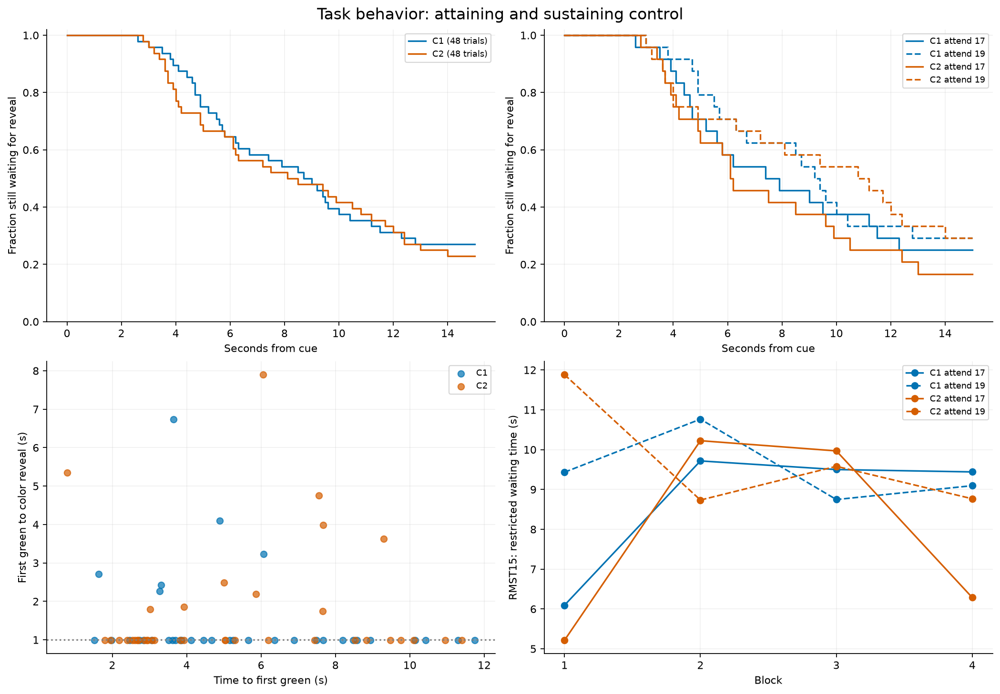

,cue,attended_hz,n,reveals,RMST15_s,first_green_RMST15_s,median_observed_reveal_s,median_first_green_to_reveal_s,green_reached_but_timeout
0,c1,17.0,24,18,8.687520,6.117450,5.641870,0.992687,4
1,c1,19.0,24,17,9.509820,7.837620,6.652808,0.991708,3
2,c2,17.0,24,20,7.923133,5.589024,5.900879,0.992168,3
3,c2,19.0,24,17,9.740686,7.980023,7.190407,0.992414,2


In [4]:
behavior_summary=trials.groupby(['cue','attended_hz']).agg(n=('trial_id','size'),reveals=('revealed','sum'),RMST15_s=('wait15_s','mean'),first_green_RMST15_s=('first_green_wait15_s','mean'),median_observed_reveal_s=('reveal_s','median'),median_first_green_to_reveal_s=('green_to_reveal_s','median'),green_reached_but_timeout=('green_timeout','sum')).reset_index()
behavior_summary.to_csv(OUT/'behavior_timing_summary.csv',index=False)
fig,axes=plt.subplots(2,2,figsize=(13,9),layout='constrained');grid=np.linspace(0,15,151)
for cue in ['c1','c2']:
 g=trials[trials.cue.eq(cue)];surv=[1-np.count_nonzero(g.revealed & g.reveal_s.le(t))/len(g) for t in grid]
 axes[0,0].step(grid,surv,where='post',color=COLORS[cue],label=f'{cue.upper()} (48 trials)')
 for hz,ls in [(17.,'-'),(19.,'--')]:
  gg=g[g.attended_hz.eq(hz)];ss=[1-np.count_nonzero(gg.revealed & gg.reveal_s.le(t))/len(gg) for t in grid]
  axes[0,1].step(grid,ss,where='post',color=COLORS[cue],ls=ls,label=f'{cue.upper()} attend {hz:g}')
  v=gg.groupby('block').wait15_s.mean();axes[1,1].plot(v.index,v.values,marker='o',color=COLORS[cue],ls=ls,label=f'{cue.upper()} attend {hz:g}')
 gg=g[g.revealed];axes[1,0].scatter(gg.first_green_s,gg.green_to_reveal_s,color=COLORS[cue],alpha=.7,label=cue.upper())
for ax in axes[0]:ax.set(xlabel='Seconds from cue',ylabel='Fraction still waiting for reveal',ylim=(0,1.02))
axes[1,0].axhline(1,color='gray',ls=':');axes[1,0].set(xlabel='Time to first green (s)',ylabel='First green to color reveal (s)')
axes[1,1].set(xlabel='Block',ylabel='RMST15: restricted waiting time (s)',xticks=[1,2,3,4])
for ax in axes.flat:ax.legend(fontsize=8)
savefig(fig,'behavior_reveal_timing','Task behavior: attaining and sustaining control','All blocks pooled except the scalar block comparison. Timeouts are censored. First-green-to-reveal points include revealed trials only.');display(behavior_summary)

## Timing outcomes across blocks: C1 pointing and C2 motion

Every panel uses **block 1-4 on the x-axis**. Dots are trial observations; thick curves
are medians and vertical bars are interquartile ranges, not confidence intervals.
Reaction time includes **all valid recorded responses**, irrespective of correctness,
and is measured from color reveal. Other intervals use the game's recorded event times.
Open triangles mark right-censored intervals; they do not enter observed-event medians.
The separate restricted-mean panel includes the 15-second censored tail for cue-to-reveal
and cue-to-first-green timing, allowing comparison without discarding timeout trials.
Frequency-specific plots retain the 17/19 Hz swap factor. Blocks contain 12 trials per cue,
six per attended frequency. Differences are descriptive for this participant; connecting
block summaries does not establish a learning effect.


A late first-green entry may leave less than the required one-second hold before the deadline; reaching green without reveal does not always imply an interrupted hold.

Timing checked: 96 trials; RT includes all valid recorded responses; censored intervals reported separately.



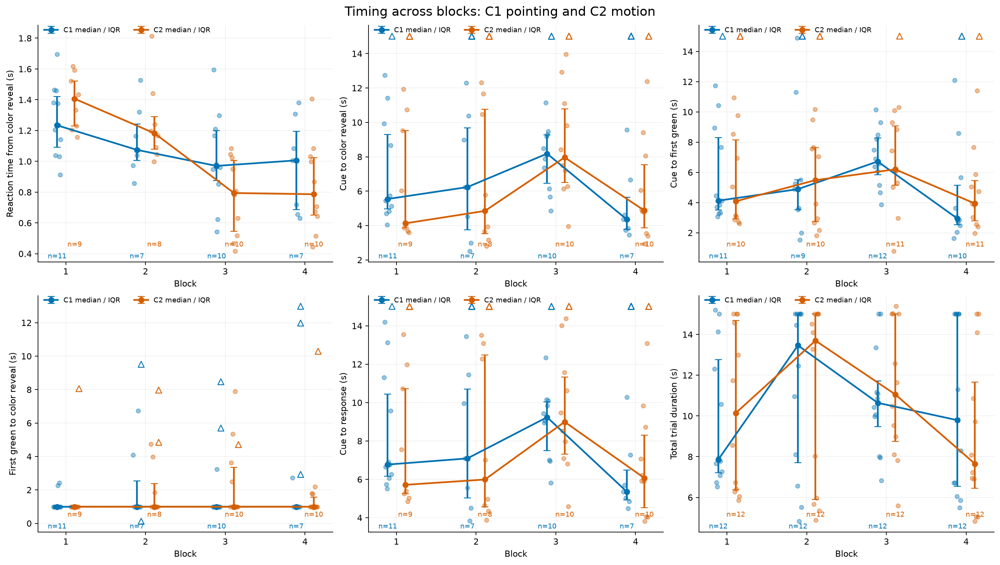


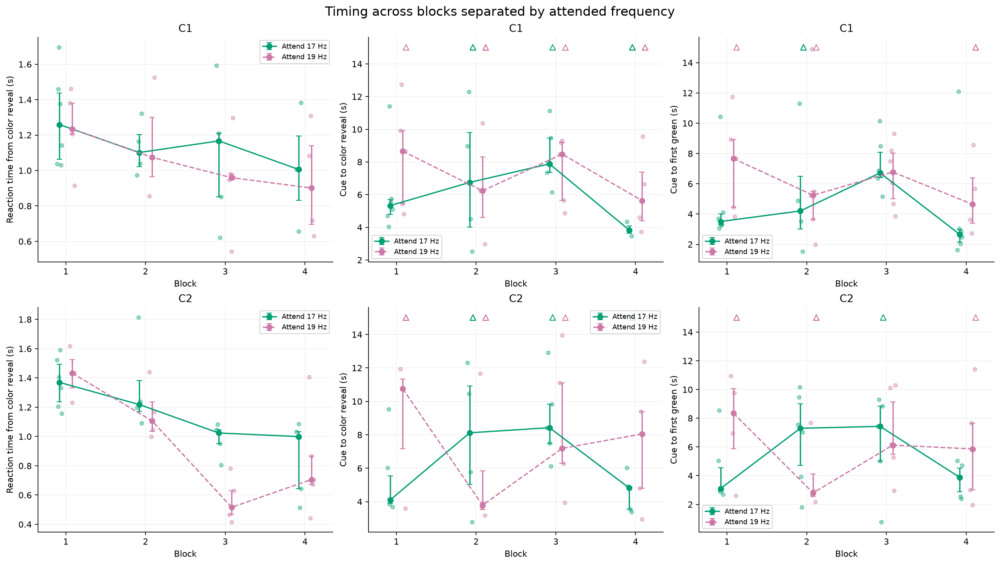


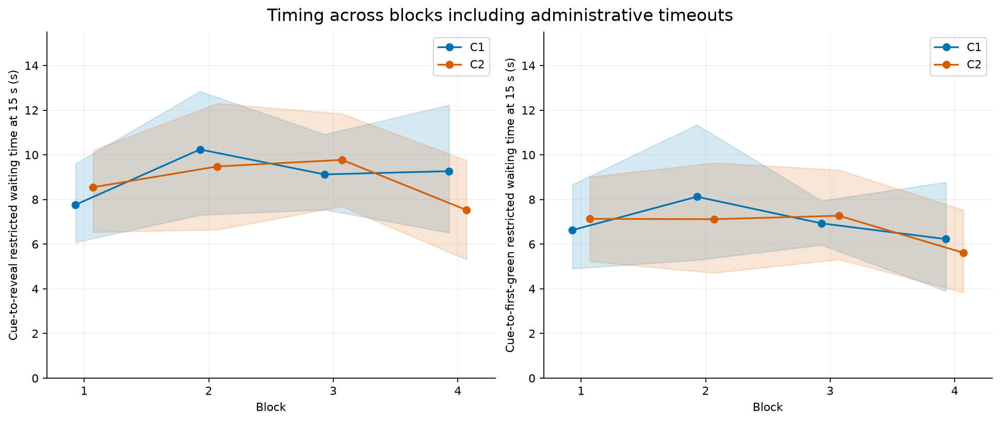

metric     cue_to_green_s  cue_to_response_s  ...   rt_s  trial_duration_s
block cue                                     ...                         
1     c1            4.123              6.773  ...  1.234             7.854
      c2            4.084              5.716  ...  1.407            10.144
2     c1            4.888              7.091  ...  1.075            13.462
      c2            5.483              5.992  ...  1.183            13.697
3     c1            6.718              9.238  ...  0.970            10.644
      c2            6.198              8.998  ...  0.794            11.061
4     c1            2.941              5.358  ...  1.006             9.792
      c2            3.933              6.070  ...  0.786             7.653

[8 rows x 8 columns]

In [18]:

timing_tables=[]
for block in range(1,5):
 frame=pd.read_csv(DATA_ROOT/'gameData'/f'p7_b{block}_leaves_trialdata.csv')
 frame['block']=block;frame['cue']=frame.Cue
 frame['attended_hz']=np.where(frame.Cue.eq('c1'),frame.FrequencyC1Hz,frame.FrequencyC2Hz)
 valid=frame.ParticipantResponse.isin(['up','down','left','right']) & frame.ReactionTime.ge(0) & frame.RevealTimeout.eq(0) & frame.ResponseTimeout.eq(0)
 revealed=frame.RevealTimeout.eq(0) & frame.ColorOnsetTime.notna()
 green=frame.FirstGreenTime.notna()
 frame['rt_s']=frame.ReactionTime.where(valid)
 frame['cue_to_reveal_s']=(frame.ColorOnsetTime-frame.CueOnsetTime).where(revealed)
 frame['cue_to_green_s']=(frame.FirstGreenTime-frame.CueOnsetTime).where(green)
 frame['green_to_reveal_s']=(frame.ColorOnsetTime-frame.FirstGreenTime).where(revealed & green)
 frame['cue_to_response_s']=(frame.ColorOnsetTime+frame.ReactionTime-frame.CueOnsetTime).where(valid)
 frame['trial_duration_s']=frame.TrialEnd-frame.TrialStart
 frame['cue_to_reveal_censored_s']=(frame.TrialEnd-frame.CueOnsetTime).where(~revealed)
 frame['cue_to_green_censored_s']=(frame.TrialEnd-frame.CueOnsetTime).where(~green)
 frame['green_to_reveal_censored_s']=(frame.TrialEnd-frame.FirstGreenTime).where(~revealed & green)
 frame['cue_to_response_censored_s']=(frame.TrialEnd-frame.CueOnsetTime).where(~valid)
 frame['reveal_wait15_s']=np.minimum(frame.cue_to_reveal_s.fillna(frame.TrialEnd-frame.CueOnsetTime),15.)
 frame['green_wait15_s']=np.minimum(frame.cue_to_green_s.fillna(frame.TrialEnd-frame.CueOnsetTime),15.)
 assert frame.groupby('cue').size().eq(12).all()
 assert np.allclose(frame.loc[valid,'cue_to_response_s'],frame.loc[valid,'cue_to_reveal_s']+frame.loc[valid,'rt_s'])
 assert frame.loc[frame.RevealTimeout.eq(1),'trial_duration_s'].between(14.9,15.2).all()
 timing_tables.append(frame)
timing_trials=pd.concat(timing_tables,ignore_index=True)
TIMING_METRICS=[('rt_s','Reaction time from color reveal (s)',None),('cue_to_reveal_s','Cue to color reveal (s)','cue_to_reveal_censored_s'),('cue_to_green_s','Cue to first green (s)','cue_to_green_censored_s'),('green_to_reveal_s','First green to color reveal (s)','green_to_reveal_censored_s'),('cue_to_response_s','Cue to response (s)','cue_to_response_censored_s'),('trial_duration_s','Total trial duration (s)',None)]
def summarize_timing(keys):
 rows=[]
 for key,g in timing_trials.groupby(keys):
  if not isinstance(key,tuple):key=(key,)
  for metric,label,censor in TIMING_METRICS+[("reveal_wait15_s","Restricted cue-to-reveal waiting time (s)",None),("green_wait15_s","Restricted cue-to-first-green waiting time (s)",None)]:
   v=g[metric].dropna();row=dict(zip(keys,key))
   row.update(metric=metric,n_trials=len(g),n_observed=len(v),n_censored=int(g[censor].notna().sum()) if censor else 0,mean_s=v.mean(),median_s=v.median(),q25_s=v.quantile(.25),q75_s=v.quantile(.75),std_s=v.std())
   rows.append(row)
 return pd.DataFrame(rows)
timing_summary=summarize_timing(['block','cue'])
timing_frequency_summary=summarize_timing(['block','cue','attended_hz'])
timing_trials.to_csv(OUT/'timing_trials.csv',index=False)
timing_summary.to_csv(OUT/'timing_by_block_condition.csv',index=False)
timing_frequency_summary.to_csv(OUT/'timing_by_block_condition_frequency.csv',index=False)
fig,axes=plt.subplots(2,3,figsize=(16,9),layout='constrained')
for ax,(metric,label,censor) in zip(axes.flat,TIMING_METRICS):
 for cue,offset in [('c1',-.11),('c2',.11)]:
  summary=timing_summary[timing_summary.cue.eq(cue)&timing_summary.metric.eq(metric)].sort_values('block')
  ax.errorbar(summary.block+offset,summary.median_s,yerr=np.vstack([summary.median_s-summary.q25_s,summary.q75_s-summary.median_s]),fmt='-o',color=COLORS[cue],capsize=4,lw=2,label=cue.upper()+' median / IQR')
  for block in range(1,5):
   g=timing_trials[timing_trials.block.eq(block)&timing_trials.cue.eq(cue)]
   v=g[metric].dropna().to_numpy();jitter=np.linspace(-.045,.045,len(v))
   ax.scatter(block+offset+jitter,v,color=COLORS[cue],alpha=.4,s=23,zorder=2)
   if censor:
    cv=g[censor].dropna().to_numpy()
    ax.scatter(np.full(len(cv),block+offset+.055),cv,marker='^',facecolors='none',edgecolors=COLORS[cue],s=48,zorder=3)
   n=int(summary.loc[summary.block.eq(block),'n_observed'].iloc[0])
   ax.text(block+offset,.015 if cue=='c1' else .065,f'n={n}',transform=ax.get_xaxis_transform(),ha='center',fontsize=8,color=COLORS[cue])
 ax.set(xlabel='Block',ylabel=label,xticks=[1,2,3,4],xlim=(.65,4.35));ax.legend(fontsize=8,loc='upper left',bbox_to_anchor=(0,1.02),ncol=2,frameon=False)
savefig(fig,'timing_across_blocks_c1_c2','Timing across blocks: C1 pointing and C2 motion','Every panel uses block on the x-axis. Dots: individual trials; lines: medians; bars: IQR. Open triangles: right-censored intervals, excluded from observed-event medians. Reaction times include all valid responses, independent of accuracy. n labels give observed values per cue/block.')
fig,axes=plt.subplots(2,3,figsize=(16,9),layout='constrained')
for row,cue in enumerate(['c1','c2']):
 for col,(metric,label,censor) in enumerate(TIMING_METRICS[:3]):
  ax=axes[row,col]
  for hz,color,ls,offset in [(17.,'#009E73','-',-.08),(19.,'#CC79A7','--',.08)]:
   ss=timing_frequency_summary[timing_frequency_summary.cue.eq(cue)&timing_frequency_summary.attended_hz.eq(hz)&timing_frequency_summary.metric.eq(metric)].sort_values('block')
   ax.errorbar(ss.block+offset,ss.median_s,yerr=np.vstack([ss.median_s-ss.q25_s,ss.q75_s-ss.median_s]),marker='o',ls=ls,color=color,capsize=3,label=f'Attend {hz:g} Hz')
   for block in range(1,5):
    g=timing_trials[timing_trials.block.eq(block)&timing_trials.cue.eq(cue)&timing_trials.attended_hz.eq(hz)]
    v=g[metric].dropna().to_numpy();ax.scatter(block+offset+np.linspace(-.03,.03,len(v)),v,s=19,color=color,alpha=.4)
    if censor:
     cv=g[censor].dropna().to_numpy();ax.scatter(np.full(len(cv),block+offset+.04),cv,marker='^',facecolors='none',edgecolors=color,s=42)
  ax.set(title=cue.upper(),xlabel='Block',ylabel=label,xticks=[1,2,3,4],xlim=(.65,4.35));ax.legend(fontsize=8)
savefig(fig,'timing_across_blocks_frequency','Timing across blocks separated by attended frequency','C1 top row; C2 bottom row. Six trials per cue x frequency x block. Lines: observed-event median; bars: IQR; dots: individual trials; open triangles: censored. All valid reaction times are included.')
fig,axes=plt.subplots(1,2,figsize=(12,5),layout='constrained')
rng=np.random.default_rng(20261104)
restricted_rows=[]
for ax,metric,label in zip(axes,['reveal_wait15_s','green_wait15_s'],['Cue-to-reveal restricted waiting time at 15 s (s)','Cue-to-first-green restricted waiting time at 15 s (s)']):
 for cue,offset in [('c1',-.07),('c2',.07)]:
  means=[];lows=[];highs=[]
  for block in range(1,5):
   g=timing_trials[timing_trials.block.eq(block)&timing_trials.cue.eq(cue)]
   by_hz=[g.loc[g.attended_hz.eq(hz),metric].to_numpy() for hz in [17.,19.]]
   draws=np.mean([rng.choice(v,(2000,len(v)),replace=True).mean(1) for v in by_hz],axis=0)
   mean=g[metric].mean();lo,hi=np.quantile(draws,[.025,.975]);means.append(mean);lows.append(lo);highs.append(hi)
   restricted_rows.append(dict(block=block,cue=cue,metric=metric,n_trials=len(g),restricted_mean_s=mean,ci_low_s=lo,ci_high_s=hi))
  xx=np.arange(1,5)+offset;ax.plot(xx,means,'-o',color=COLORS[cue],label=cue.upper());ax.fill_between(xx,lows,highs,color=COLORS[cue],alpha=.16)
 ax.set(xlabel='Block',ylabel=label,xticks=[1,2,3,4],xlim=(.7,4.3),ylim=(0,15.5));ax.legend()
pd.DataFrame(restricted_rows).to_csv(OUT/'restricted_timing_by_block.csv',index=False)
savefig(fig,'restricted_timing_across_blocks','Timing across blocks including administrative timeouts','All 12 trials per cue/block contribute. Right-censored waiting times contribute the known 15-second tail to restricted means. Shading: 95% trial-bootstrap intervals, resampling within attended-frequency cells; conditional on this participant and block.')
display(timing_summary.pivot_table(index=['block','cue'],columns='metric',values='median_s').round(3))
print('Timing checked: 96 trials; RT includes all valid recorded responses; censored intervals reported separately.')


In [5]:
def reference_matrix(time_seconds, frequencies_hz):
    t = np.asarray(time_seconds, dtype=float)
    return np.column_stack([func(2*np.pi*f*t)
                            for f in frequencies_hz for func in (np.sin, np.cos)])

def joint_reference(time_seconds):
    return reference_matrix(time_seconds, TARGETS_HZ)

def whitening_basis(centered):
    # Direct data SVD avoids squaring the condition number through X.T @ X.
    q, singular_values, rotation = np.linalg.svd(centered, full_matrices=False)
    tolerance = max(centered.shape) * np.finfo(float).eps * singular_values[0]
    keep = singular_values > tolerance
    if not np.any(keep):
        raise ValueError('No nonzero variance for CCA')
    return rotation[keep].T / singular_values[keep], q[:, keep]

def fit_cca_projection(eeg_uv, time_seconds, frequencies_hz):
    x, y = np.asarray(eeg_uv, float), reference_matrix(time_seconds, frequencies_hz)
    if x.ndim != 2 or x.shape[0] != y.shape[0] or x.shape[1] != len(CHANNEL_COLUMNS):
        raise ValueError('Expected samples x selected channels and matching reference times')
    if len(x) <= x.shape[1]+y.shape[1] or not np.isfinite(x).all():
        raise ValueError('Insufficient samples or non-finite EEG')
    x_mean, y_mean = x.mean(axis=0), y.mean(axis=0)
    xc, yc = x-x_mean, y-y_mean
    (bx, qx), (by, qy) = whitening_basis(xc), whitening_basis(yc)
    left, strengths, right = np.linalg.svd(qx.T @ qy, full_matrices=False)
    w, v = bx @ left[:, 0], by @ right[0]
    w /= np.linalg.norm(w)
    v /= np.linalg.norm(v)
    anchor = SIGN_ANCHOR_INDEX
    fallback = anchor is None or abs(w[anchor]) <= 1e-12
    if fallback:
        anchor = int(np.argmax(np.abs(w)))
    if w[anchor] < 0:
        w, v = -w, -v
    u = xc @ w
    rho = float(np.corrcoef(u, yc @ v)[0, 1])
    if not np.isfinite(rho):
        raise ValueError('Degenerate projected variance')
    return dict(w=w, v=v, x_mean=x_mean, y_mean=y_mean, u=u, rho=rho,
                rho_svd=float(np.clip(strengths[0], 0, 1)), x_rank=bx.shape[1],
                y_rank=by.shape[1], sign_fallback=fallback,
                frequencies_hz=tuple(frequencies_hz), reference_columns=y.shape[1])

def fit_joint_cca(eeg_uv, time_seconds):
    return fit_cca_projection(eeg_uv, time_seconds, TARGETS_HZ)

def fit_target_cca(eeg_uv, time_seconds, target_hz):
    # Exactly two reference columns; each call estimates its own EEG weights.
    return fit_cca_projection(eeg_uv, time_seconds, (float(target_hz),))

@lru_cache(maxsize=None)
def dpss_taper(n_samples):
    return signal.windows.dpss(n_samples, NW=1, Kmax=1, sym=False)[0]

def psd(data, nfft=None):
    x = np.asarray(data, float)
    return signal.periodogram(x, fs=FS, window=dpss_taper(len(x)), nfft=len(x) if nfft is None else nfft,
        detrend='constant', return_onesided=True, scaling='density', axis=0)

def db(power):
    return 10*np.log10(np.maximum(np.asarray(power), np.finfo(float).tiny))

# Known linear mixture, rank deficiency, scaling, and phase-cancellation checks.
rng = np.random.default_rng(17)
t_test = np.arange(1000)/FS
r_test = joint_reference(t_test)
x_test = r_test @ rng.normal(size=(4, len(CHANNEL_COLUMNS)))
x_test += rng.normal(scale=.01, size=x_test.shape)
fit_test = fit_joint_cca(x_test, t_test)
assert fit_test['rho'] > .999
assert np.isclose(np.linalg.norm(fit_test['w']), 1)
assert np.isclose(fit_test['rho'], fit_test['rho_svd'], atol=1e-10)
assert fit_joint_cca(np.tile(r_test[:, :1], (1, len(CHANNEL_COLUMNS))), t_test)['x_rank'] == 1
assert len(psd(fit_test['u'])[0]) == 501
for target in TARGETS_HZ:
    # A target-specific mixture supports this check even with one selected channel.
    target_ref = reference_matrix(t_test, (target,))
    target_eeg = target_ref @ rng.normal(size=(2, len(CHANNEL_COLUMNS)))
    target_eeg += rng.normal(scale=.001, size=target_eeg.shape)
    single = fit_target_cca(target_eeg, t_test, target)
    assert single['reference_columns'] == 2 and single['rho'] > .999
if len(CHANNEL_COLUMNS) >= 2:
    # Independent spatial sources require at least two selected channels.
    x_two = np.zeros((1000, len(CHANNEL_COLUMNS)))
    x_two[:, 0], x_two[:, 1] = r_test[:, 0], r_test[:, 2]
    fit17 = fit_target_cca(x_two, t_test, 17)
    fit19 = fit_target_cca(x_two, t_test, 19)
    assert fit17['rho'] > .999999 and fit19['rho'] > .999999
    assert abs(np.corrcoef(fit17['u'], fit19['u'])[0, 1]) < 1e-10
sine = np.sin(2*np.pi*17*np.arange(500)/FS)
assert psd(np.mean([sine, -sine], axis=0))[1].max() == 0
assert np.mean([psd(sine)[1], psd(-sine)[1]], axis=0).max() > 0
print('CCA recovery, rank handling, scaling and averaging-order checks passed.')

CCA recovery, rank handling, scaling and averaging-order checks passed.


## Projected power every 100 ms

For every logged endpoint, fit separate 17/19 Hz spatial filters on its trailing 1 s.
P17/P19 are matched projection target-bin PSD integrated over the 1 Hz bin (microvolts
squared). Also export full projected mean-square power. Difference = attended minus
distractor; dB ratio = 10 log10(P_att/P_dist). Unit-norm spatial filters define the scaling.

Sensitivity check: fit weights on the preceding **non-overlapping second**, apply to the
current second, and calculate target-bin power there. This is out-of-fitting-window
power, not a firmware replay. Only windows entirely within cue-to-color/timeout enter
pooled task spectra. Baseline/post-reveal windows are reserved for event-locked analyses.

In [6]:
F=np.fft.rfftfreq(250,1/FS);TAPER=signal.windows.dpss(250,1,Kmax=1,sym=False)[0];DEN=FS*np.sum(TAPER*TAPER)
def spectrum_window(x):
 x=np.asarray(x);z=x-x.mean(axis=0);p=abs(np.fft.rfft(z*TAPER[:,None],axis=0))**2/DEN;p[1:-1]*=2;return p
def fit_weights(x):
 fits=[fit_target_cca(x,np.arange(250)/FS,hz) for hz in TARGETS_HZ]
 return np.column_stack([f['w'] for f in fits]),np.array([f['rho'] for f in fits])
window_rows=[];spec_rows=[];spec_u=[];spec_previous=[];spec_mean=[];spec_channel=[]
for block,rec in records.items():
 print('Reconstructing block',block,flush=True);x,seq,features=rec['x'],rec['seq'],rec['f']
 for tr in trials[trials.block.eq(block)].itertuples():
  fl=features[(features.seq>=tr.start_seq-2*FS)&(features.seq<=tr.stop_seq)]
  for q in fl.itertuples():
   pos=int(q.seq-seq[0]);a=pos-249;b=pos+1
   if a<250:continue
   current=x[a:b];w,rho=fit_weights(current);u=(current-current.mean(0))@w
   prior=x[a-250:a];wp,_=fit_weights(prior);up=(current-current.mean(0))@wp
   pu=spectrum_window(u);pp=spectrum_window(up);p17,p19=pu[17,0],pu[19,1];p17f,p19f=pp[17,0],pp[19,1]
   sign=1. if tr.attended_hz==17 else -1.;cue_time=(q.seq-tr.start_seq)/FS
   reveal_time=(q.seq-tr.reveal_seq)/FS if tr.revealed else np.nan
   endpoint_limit=tr.reveal_seq if tr.revealed else tr.stop_seq;precolor_full=bool(seq[a]>=tr.start_seq and q.seq<endpoint_limit)
   row=dict(trial_id=tr.trial_id,block=block,cue=tr.cue,attended_hz=tr.attended_hz,revealed=tr.revealed,seq=int(q.seq),fit_start_seq=int(seq[a]),cue_time=cue_time,reveal_time=reveal_time,precolor_full=precolor_full,P17=p17,P19=p19,total17=float(np.mean(u[:,0]**2)),total19=float(np.mean(u[:,1]**2)),power_diff=sign*(p17-p19),power_db=sign*float(db(p17)-db(p19)),power_db_previous=sign*float(db(p17f)-db(p19f)),power_diff_previous=sign*(p17f-p19f),score17=q.v3,score19=q.v4,score_att=q.v3 if sign==1 else q.v4,score_dist=q.v4 if sign==1 else q.v3,score_diff=sign*(q.v3-q.v4),control=q.v1 if sign==1 else q.v2,offline_rho17=rho[0],offline_rho19=rho[1],P_att=p17 if sign==1 else p19,P_dist=p19 if sign==1 else p17)
   window_rows.append(row)
   if precolor_full:
    spec_rows.append(dict(trial_id=tr.trial_id,block=block,cue=tr.cue,attended_hz=tr.attended_hz,seq=int(q.seq)))
    spec_u.append(pu);spec_previous.append(pp);spec_mean.append(spectrum_window(current.mean(axis=1,keepdims=True))[:,0]);spec_channel.append(spectrum_window(current).mean(axis=1))
windows=pd.DataFrame(window_rows);spec_meta=pd.DataFrame(spec_rows)
SU=np.stack(spec_u);SP=np.stack(spec_previous);SM=np.stack(spec_mean);SC=np.stack(spec_channel)
windows.to_csv(OUT/'rolling_100ms_metrics.csv',index=False);spec_meta.to_csv(OUT/'rolling_spectra_membership.csv',index=False)
np.savez_compressed(OUT/'rolling_window_spectra.npz',frequency=F,same_window=SU,preceding_window=SP,channel_mean=SM,mean_channel_psd=SC)
assert windows.groupby('trial_id').size().ge(30).all()
print('Reconstructed',len(windows),'windows;',len(spec_meta),'full task windows')

Reconstructing block 1
Reconstructing block 2
Reconstructing block 3
Reconstructing block 4
Reconstructed 12024 windows; 7646 full task windows


## Spectra pooled across all four blocks

Average window PSD within trial, then average trials equally. Each cue x frequency cell
contains 24 trials, six per block. Compare same-window versus preceding-window CCA weights;
retain the distinction between PSD of channel mean and mean of channel PSDs.


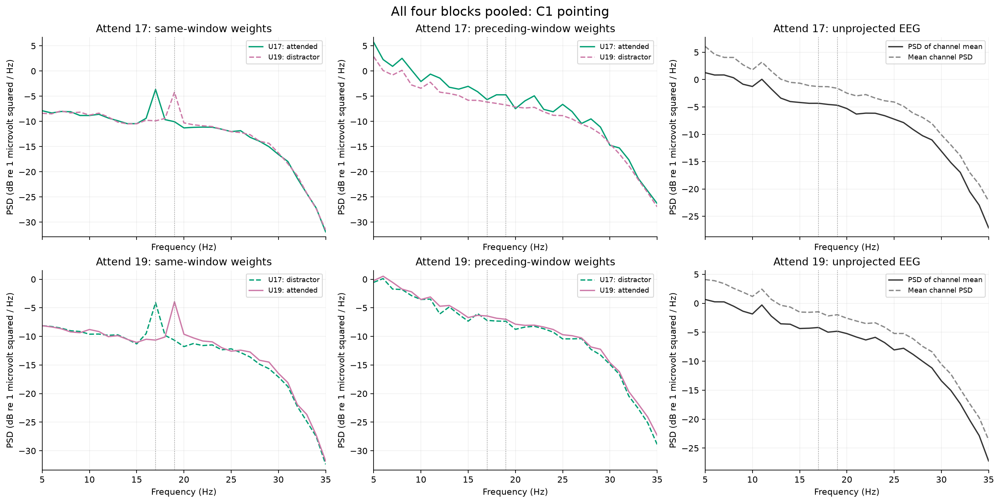


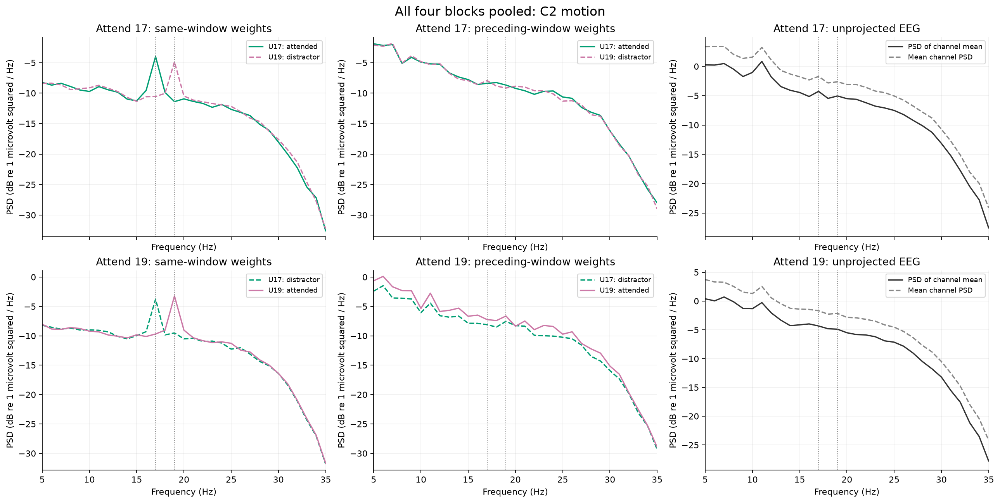

In [7]:
trial_spectra={}
for tid,g in spec_meta.groupby('trial_id',sort=False):
 ix=g.index.to_numpy();trial_spectra[tid]=(SU[ix].mean(0),SP[ix].mean(0),SM[ix].mean(0),SC[ix].mean(0))
pooled_rows=[]
for cue in ['c1','c2']:
 fig,axes=plt.subplots(2,3,figsize=(16,8),layout='constrained',sharex=True);mask=(F>=5)&(F<=35)
 for r,hz in enumerate(TARGETS_HZ):
  ids=trials.loc[trials.cue.eq(cue)&trials.attended_hz.eq(hz),'trial_id'];assert len(ids)==24
  pooled=[np.mean([trial_spectra[tid][j] for tid in ids],axis=0) for j in range(4)];limits=[]
  for col,p in enumerate(pooled[:2]):
   for j,target in enumerate(TARGETS_HZ):
    axes[r,col].plot(F[mask],db(p[mask,j]),color=FREQCOL[target],ls='-' if target==hz else '--',label=f'U{target:g}: '+('attended' if target==hz else 'distractor'))
    pooled_rows.append(pd.DataFrame(dict(cue=cue,attended_hz=hz,method=['same_window','preceding_window'][col],component=f'U{target:g}',frequency_hz=F,power_uv2_per_hz=p[:,j],n_trials=24)))
   limits.extend(db(p[mask]).ravel());axes[r,col].set(title=f'Attend {hz:g}: '+['same-window weights','preceding-window weights'][col])
  for ax in axes[r,:2]:ax.set_ylim(np.min(limits)-1,np.max(limits)+1)
  axes[r,2].plot(F[mask],db(pooled[2][mask]),label='PSD of channel mean',color='#333333');axes[r,2].plot(F[mask],db(pooled[3][mask]),label='Mean channel PSD',color='#888888',ls='--');axes[r,2].set(title=f'Attend {hz:g}: unprojected EEG')
  for ax in axes[r]:
   for target in TARGETS_HZ:ax.axvline(target,color='gray',ls=':',lw=.8)
   ax.set(xlabel='Frequency (Hz)',ylabel='PSD (dB re 1 microvolt squared / Hz)',xlim=(5,35));ax.legend(fontsize=8)
 savefig(fig,f'pooled_spectra_{cue}',f'All four blocks pooled: {cue.upper()} '+('pointing' if cue=='c1' else 'motion'),'24 equally weighted trials per row. Full 1-second windows updated every 100 ms; native 1 Hz resolution. Average linear power before dB. Same-data fitting alone cannot establish an attention effect.')
pd.concat(pooled_rows).to_csv(OUT/'pooled_rolling_spectra.csv',index=False)

## Cue-locked and color-reveal-locked power, score and control time series

Average within trial/bin, then across trials. Shading is between-trial SEM for description,
not a timepoint-wise test. Plot support: early reveal-locked times contain longer trials;
late cue-locked times contain trials that have not yet revealed. No missing tails are extended.
100 ms bins use floor(t/0.1), displayed at centers. Current power/score describes the trailing
second. Post-reveal activity includes visual changes and response preparation; its first second
also contains pre-trigger EEG. Pre-color task windows must be entirely after cue onset.


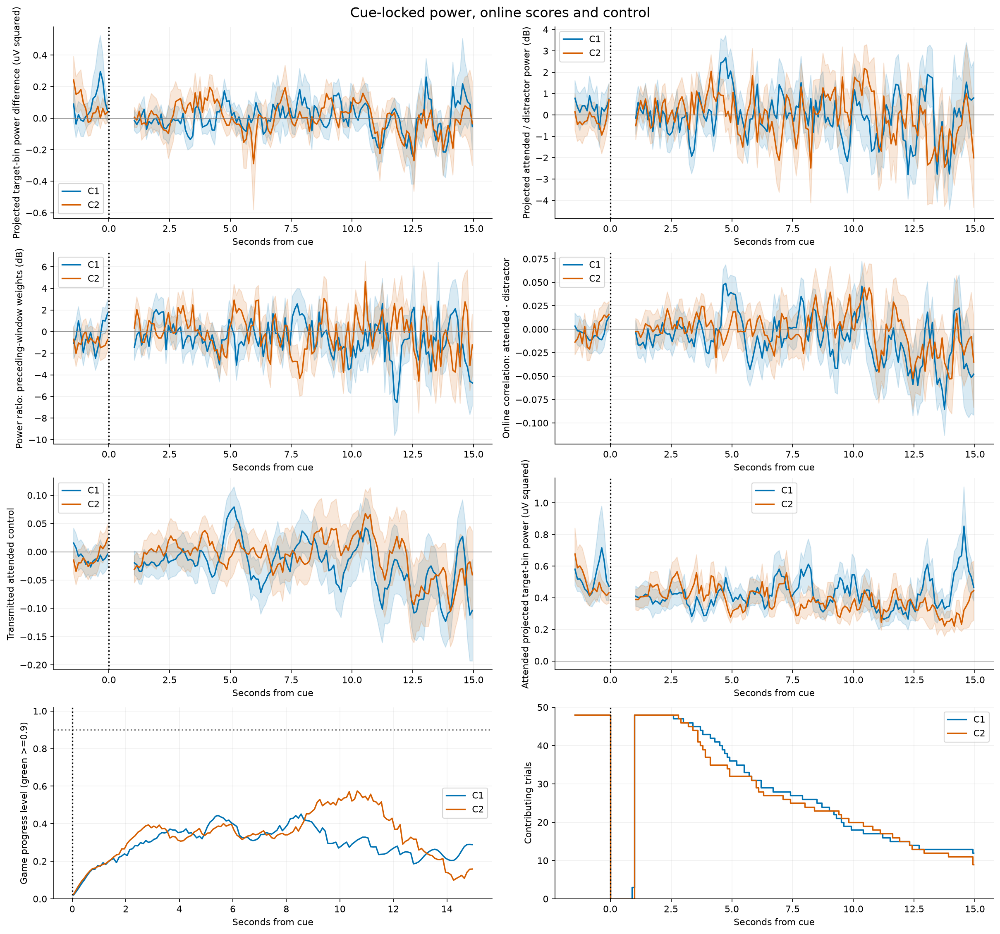


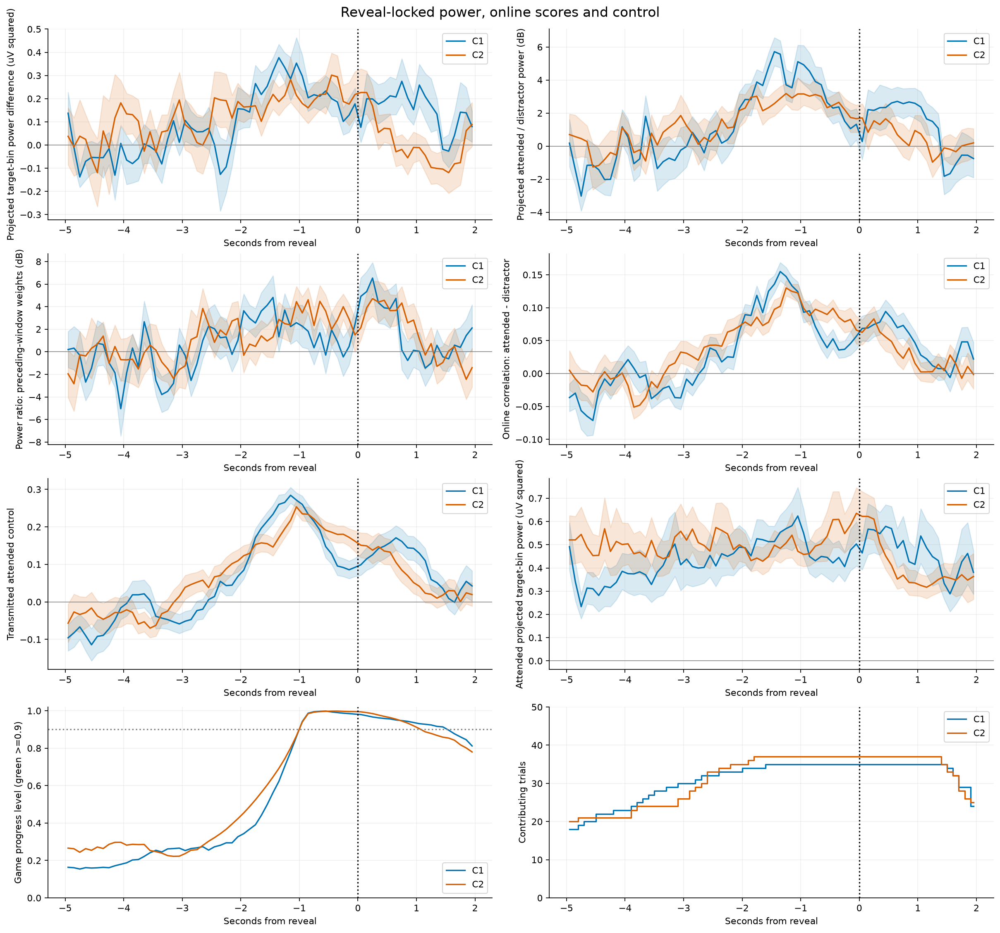


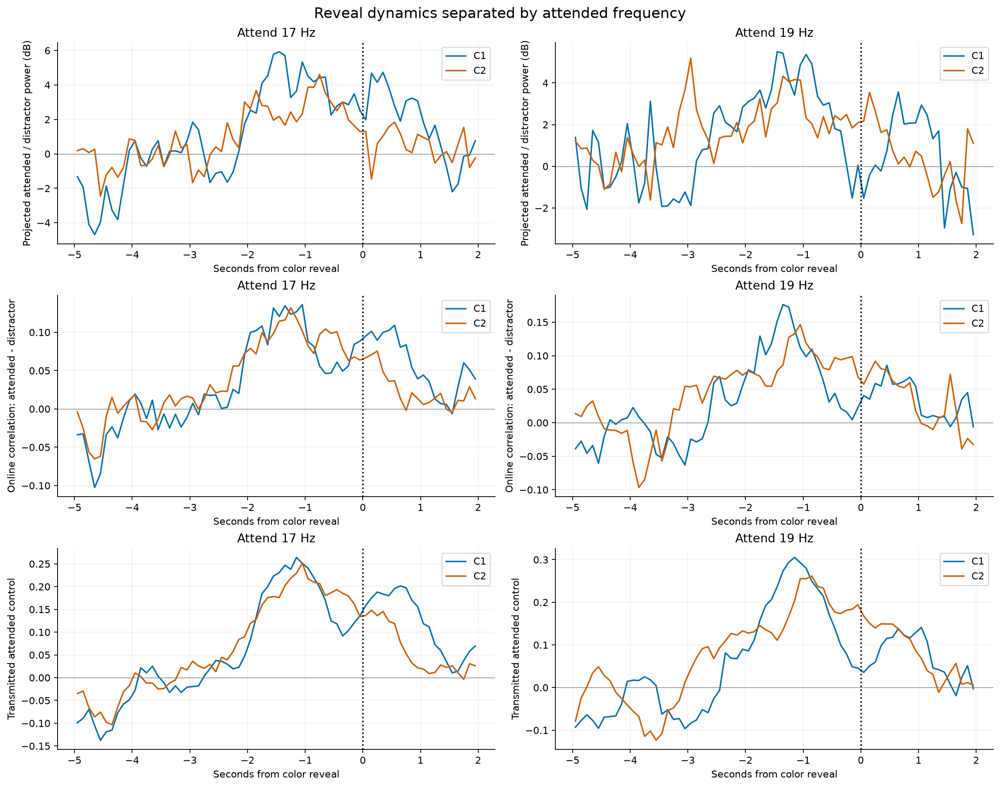

In [8]:
METRICS=[('power_diff','Projected target-bin power difference (uV squared)'),('power_db','Projected attended / distractor power (dB)'),('power_db_previous','Power ratio: preceding-window weights (dB)'),('score_diff','Online correlation: attended - distractor'),('control','Transmitted attended control'),('P_att','Attended projected target-bin power (uV squared)')]
aligned_exports=[]
def aligned(table,timecol,value,groupcols,lo,hi):
 d=table[table[timecol].ge(lo)&table[timecol].lt(hi)].copy();d['bin']=np.floor((d[timecol]+1e-8)/.1).astype(int)
 d=d.groupby(['trial_id']+groupcols+['bin'],as_index=False)[value].mean()
 a=d.groupby(groupcols+['bin'])[value].agg(['mean','std','count']);full=pd.MultiIndex.from_product([*[sorted(d[c].unique()) for c in groupcols],range(int(np.floor(lo/.1)),int(np.ceil(hi/.1)))],names=groupcols+['bin']);a=a.reindex(full).reset_index();a['count']=a['count'].fillna(0);a['time']=a['bin']*.1+.05;a['sem']=a['std']/np.sqrt(a['count'].replace(0,np.nan));return a
for lock,timecol,lo,hi in [('cue','cue_time',-1.5,15.),('reveal','reveal_time',-5.,2.)]:
 d=windows[(windows.cue_time<0)|windows.precolor_full].copy() if lock=='cue' else windows[windows.revealed & windows.cue_time.ge(1)].copy()
 fig,axes=plt.subplots(4,2,figsize=(15,14),layout='constrained')
 for ax,(metric,label) in zip(axes.flat,METRICS):
  a=aligned(d,timecol,metric,['cue'],lo,hi);a['metric']=metric;a['lock']=lock;aligned_exports.append(a)
  for cue in ['c1','c2']:
   g=a[a.cue.eq(cue)].copy();g.loc[g['count']<5,['mean','sem']]=np.nan;ax.plot(g.time,g['mean'],color=COLORS[cue],label=cue.upper());ax.fill_between(g.time,g['mean']-g['sem'],g['mean']+g['sem'],color=COLORS[cue],alpha=.15)
  ax.axvline(0,color='black',ls=':');ax.axhline(0,color='gray',lw=.7);ax.set(ylabel=label,xlabel=f'Seconds from {lock}');ax.legend()
 td=trace[trace.ColorsRevealed.eq(0)] if lock=='cue' else trace[trace.revealed]
 for cue in ['c1','c2']:
  a=aligned(td,timecol,'NFLevel',['cue'],lo,hi);g=a[a.cue.eq(cue)&a['count'].ge(5)];axes[3,0].plot(g.time,g['mean'],color=COLORS[cue],label=cue.upper())
  a=aligned(d,timecol,'score_diff',['cue'],lo,hi);g=a[a.cue.eq(cue)];axes[3,1].step(g.time,g['count'],where='mid',color=COLORS[cue],label=cue.upper())
 axes[3,0].axhline(.9,color='gray',ls=':');axes[3,0].set(ylabel='Game progress level (green >=0.9)',xlabel=f'Seconds from {lock}',ylim=(0,1.02));axes[3,1].set(ylabel='Contributing trials',xlabel=f'Seconds from {lock}',ylim=(0,50))
 for ax in axes[3]:ax.axvline(0,color='black',ls=':');ax.legend()
 savefig(fig,f'{lock}_locked_dynamics',f'{lock.capitalize()}-locked power, online scores and control','All blocks pooled. 100 ms updates, trailing 1-second estimators. Shading: between-trial SEM. Display bins with >=5 trials; counts below. Reveal-aligned growth is partly selected by the stopping rule.')
fig,axes=plt.subplots(3,2,figsize=(14,11),layout='constrained')
for col,hz in enumerate(TARGETS_HZ):
 d=windows[windows.revealed & windows.attended_hz.eq(hz) & windows.cue_time.ge(1)]
 for ax,(metric,label) in zip(axes[:,col],[METRICS[1],METRICS[3],METRICS[4]]):
  a=aligned(d,'reveal_time',metric,['cue'],-5,2)
  for cue in ['c1','c2']:
   g=a[a.cue.eq(cue)].copy();g.loc[g['count']<5,['mean','sem']]=np.nan;ax.plot(g.time,g['mean'],color=COLORS[cue],label=cue.upper())
  ax.axvline(0,color='black',ls=':');ax.axhline(0,color='gray',lw=.6);ax.set(title=f'Attend {hz:g} Hz',ylabel=label,xlabel='Seconds from color reveal');ax.legend()
savefig(fig,'reveal_locked_frequency_split','Reveal dynamics separated by attended frequency','17/19 Hz balanced within cue and block. Bins require >=5 trials. Successful-reveal selection remains.');pd.concat(aligned_exports,ignore_index=True).to_csv(OUT/'event_locked_summary.csv',index=False)

## Does pre-reveal dominance reflect target enhancement or competitor suppression?

Plot the attended and distractor signals separately in the same long-reveal cohort. This
separates two contributions that are hidden by a difference score. Mean target-bin power
is shown in linear microvolts squared; CCA correlations are the recorded online scores.


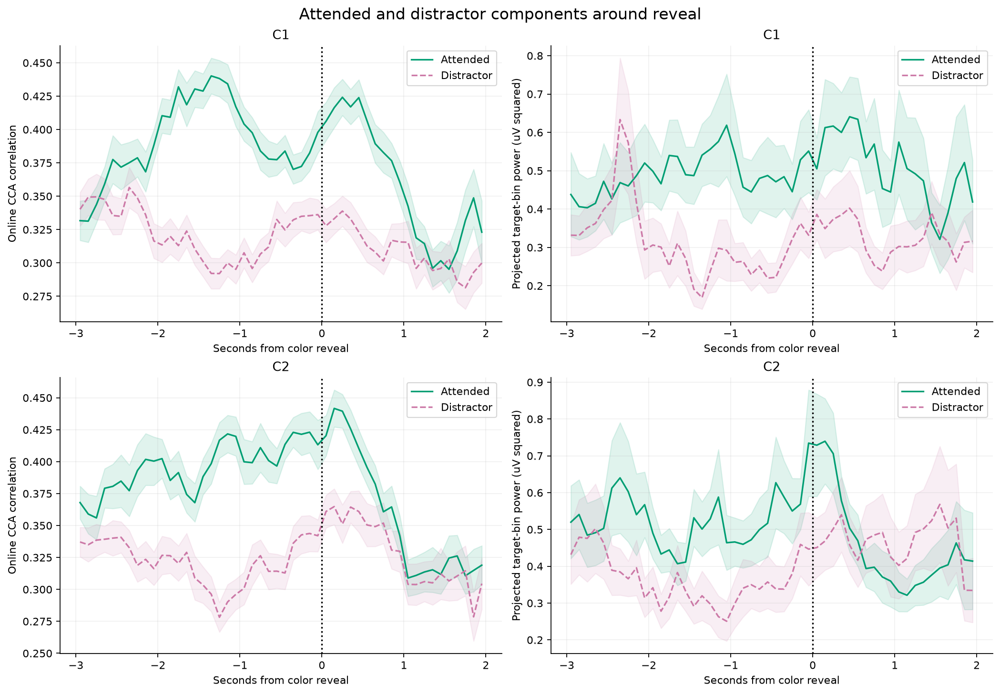

In [9]:
long_ids=trials.loc[trials.revealed & trials.reveal_s.ge(4),'trial_id']
d=windows[windows.trial_id.isin(long_ids)]
fig,axes=plt.subplots(2,2,figsize=(13,9),layout='constrained')
for row,cue in enumerate(['c1','c2']):
 for col,pairs,label in [(0,[('score_att','Attended'),('score_dist','Distractor')],'Online CCA correlation'),(1,[('P_att','Attended'),('P_dist','Distractor')],'Projected target-bin power (uV squared)')]:
  ax=axes[row,col]
  for (metric,lab),color,ls in zip(pairs,['#009E73','#CC79A7'],['-','--']):
   a=aligned(d,'reveal_time',metric,['cue'],-3,2);g=a[a.cue.eq(cue)].copy();g.loc[g['count']<5,['mean','sem']]=np.nan
   ax.plot(g.time,g['mean'],color=color,ls=ls,label=lab);ax.fill_between(g.time,g['mean']-g['sem'],g['mean']+g['sem'],color=color,alpha=.12)
  ax.axvline(0,color='black',ls=':');ax.set(title=cue.upper(),xlabel='Seconds from color reveal',ylabel=label);ax.legend()
savefig(fig,'reveal_locked_attended_distractor','Attended and distractor components around reveal',f'Fixed pre-reveal cohort: {len(long_ids)} trials with reveal latency >=4 s. Shading: between-trial SEM. Post-trigger support decreases with trial stopping. Power uses same-window fits; the separate preceding-window analysis checks fitting sensitivity.')

## Interval comparisons and block robustness

Early = endpoints 1-2 s after cue, before any trial revealed and available for all 96 trials.
Baseline = endpoints -1 to -0.1 s in the preceding ITI. Pre-reveal = -1 to -0.2 s from marker
50; earlier pre-reveal = -3 to -2 s. Compare these on a **fixed cohort with reveal latency >=4 s**,
so every source window is post-cue and membership does not change. Post-reveal = +1 to +2 s,
after no pre-trigger EEG remains in the estimator, requiring endpoint coverage.

Balance block x cue x attended-frequency cell means. Trial bootstrap resamples within these
cells (2,000 draws). Intervals describe one participant conditional on four blocks. No
100 ms window is an independent replicate; no timepoint-wise tests or confirmatory p-values.


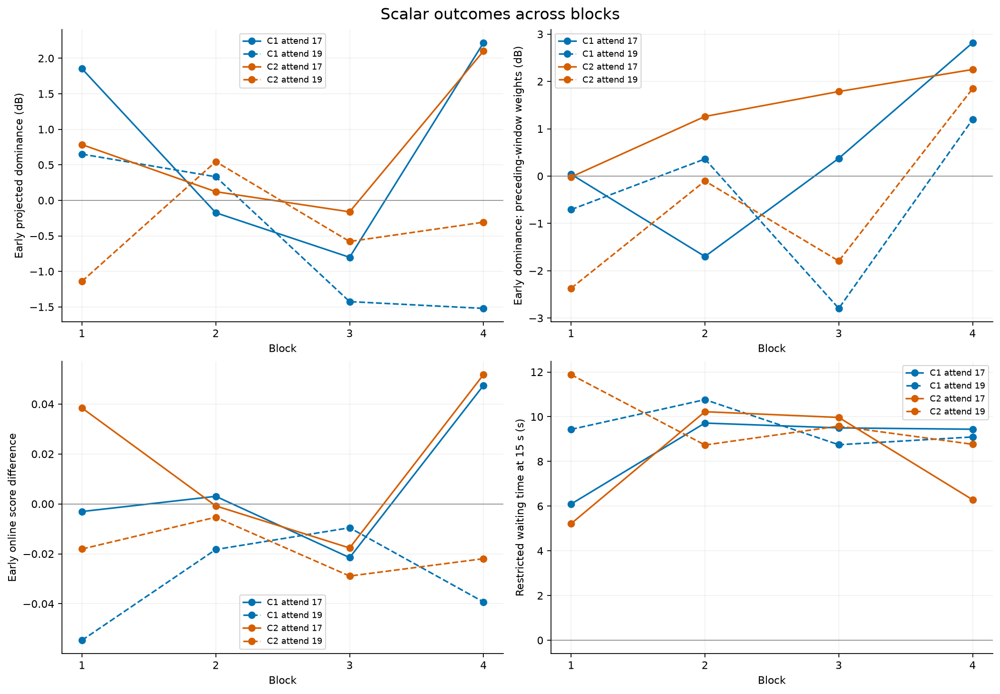

,metric,contrast,estimate,ci_low,ci_high,n_trials
0,wait15_s,C2 minus C1,-0.266760,-1.903255,1.342525,96
1,wait15_s,attend19 minus attend17,1.319926,-0.250877,2.955129,96
2,early_power_db,C2 minus C1,0.029164,-1.125813,1.190984,96
3,early_power_db,attend19 minus attend17,-1.173191,-2.377498,-0.066721,96
4,early_power_db_previous,C2 minus C1,0.409008,-1.400751,2.114521,96
5,early_power_db_previous,attend19 minus attend17,-1.397282,-3.153233,0.347215,96
6,early_score_diff,C2 minus C1,0.011662,-0.012477,0.035751,96
7,early_score_diff,attend19 minus attend17,-0.036699,-0.061153,-0.013609,96
8,early_control,C2 minus C1,0.014386,-0.029764,0.055416,96
9,early_control,attend19 minus attend17,-0.076615,-0.120952,-0.031167,96


In [10]:
trial_metrics=[]
for t in trials.itertuples():
 w=windows[windows.trial_id.eq(t.trial_id)]
 subsets={'baseline':w[w.cue_time.between(-1.,-.1)],'early':w[w.cue_time.between(1.,2.)],'pre':w[w.reveal_time.between(-1.,-.2)],'earlier':w[w.reveal_time.between(-3.,-2.) & w.cue_time.ge(1)],'post':w[w.reveal_time.between(1.,2.)]}
 row=t._asdict()
 for period,d in subsets.items():
  row[period+'_n']=len(d)
  for metric in ['power_diff','power_db','power_db_previous','score_diff','control','score_att','score_dist']:row[period+'_'+metric]=d[metric].mean() if len(d) else np.nan
 row['long_reveal']=bool(t.revealed and t.reveal_s>=4)
 row['post_complete']=bool(len(subsets['post'])>=9 and subsets['post'].reveal_time.min()<=1.1 and subsets['post'].reveal_time.max()>=1.9)
 for metric in ['power_db','power_db_previous','score_diff','control','score_att','score_dist']:
  row['early_minus_baseline_'+metric]=row['early_'+metric]-row['baseline_'+metric]
  row['pre_minus_earlier_'+metric]=row['pre_'+metric]-row['earlier_'+metric] if row['long_reveal'] else np.nan
  row['post_minus_pre_'+metric]=row['post_'+metric]-row['pre_'+metric] if row['post_complete'] else np.nan
 trial_metrics.append(row)
metrics=pd.DataFrame(trial_metrics);assert metrics.early_n.ge(9).all();metrics.to_csv(OUT/'trial_interval_metrics.csv',index=False)
RNG=np.random.default_rng(SEED)
def balanced_contrast(data,column,kind,nboot=2000):
 groups={k:g[column].dropna().to_numpy() for k,g in data.groupby(['block','cue','attended_hz'])};groups={k:v for k,v in groups.items() if len(v)}
 def value(means):
  if kind=='cue':v=[means[b,'c2',h]-means[b,'c1',h] for b in range(1,5) for h in TARGETS_HZ if (b,'c2',h) in means and (b,'c1',h) in means]
  elif kind=='frequency':v=[means[b,c,19.]-means[b,c,17.] for b in range(1,5) for c in ['c1','c2'] if (b,c,19.) in means and (b,c,17.) in means]
  else:v=list(means.values())
  return np.mean(v) if v else np.nan
 point=value({k:v.mean() for k,v in groups.items()})
 boots=np.array([value({k:RNG.choice(v,len(v),replace=True).mean() for k,v in groups.items()}) for _ in range(nboot)])
 return point,*np.quantile(boots,[.025,.975]),int(data[column].notna().sum())
contrast_rows=[]
for column in ['wait15_s','early_power_db','early_power_db_previous','early_score_diff','early_control','early_minus_baseline_power_db','early_minus_baseline_score_diff']:
 for kind in ['cue','frequency']:
  est,low,high,n=balanced_contrast(metrics,column,kind);contrast_rows.append(dict(metric=column,contrast='C2 minus C1' if kind=='cue' else 'attend19 minus attend17',estimate=est,ci_low=low,ci_high=high,n_trials=n))
for column in ['pre_minus_earlier_power_db','pre_minus_earlier_power_db_previous','pre_minus_earlier_score_diff','pre_minus_earlier_control','pre_minus_earlier_score_att','pre_minus_earlier_score_dist','post_minus_pre_power_db','post_minus_pre_score_diff']:
 d=metrics[metrics[column].notna()];est,low,high,n=balanced_contrast(d,column,'mean');contrast_rows.append(dict(metric=column,contrast='balanced paired change',estimate=est,ci_low=low,ci_high=high,n_trials=n))
contrasts=pd.DataFrame(contrast_rows);contrasts.to_csv(OUT/'exploratory_contrasts.csv',index=False)
block_metrics=metrics.groupby(['block','cue','attended_hz'])[['wait15_s','early_power_db','early_power_db_previous','early_score_diff','early_control']].mean().reset_index();block_metrics.to_csv(OUT/'block_robustness.csv',index=False)
fig,axes=plt.subplots(2,2,figsize=(13,9),layout='constrained')
for ax,metric,label in zip(axes.flat,['early_power_db','early_power_db_previous','early_score_diff','wait15_s'],['Early projected dominance (dB)','Early dominance: preceding-window weights (dB)','Early online score difference','Restricted waiting time at 15 s (s)']):
 for cue in ['c1','c2']:
  for hz,ls in [(17.,'-'),(19.,'--')]:
   g=block_metrics[block_metrics.cue.eq(cue)&block_metrics.attended_hz.eq(hz)];ax.plot(g.block,g[metric],marker='o',color=COLORS[cue],ls=ls,label=f'{cue.upper()} attend {hz:g}')
 ax.set(xlabel='Block',ylabel=label,xticks=[1,2,3,4]);ax.axhline(0,color='gray',lw=.7);ax.legend(fontsize=8)
savefig(fig,'block_scalar_robustness','Scalar outcomes across blocks','Six trials per point. Spectra remain pooled. Early endpoints 1-2 s after cue precede every reveal. Block differences are descriptive; no learning claim.');display(contrasts)

## Does early dominance accompany shorter time to reveal?

Relate trial-level early measures, before any reveal, to restricted waiting time (including
the 15 s censored tail). Center both values within block x cue x attended-frequency cells.
Association with control/score is expected under the integration rule; an association with
out-of-fitting-window power adds convergent description. This is not causal inference or a
correlation with unobserved uncensored waiting time. No significance screening is applied.


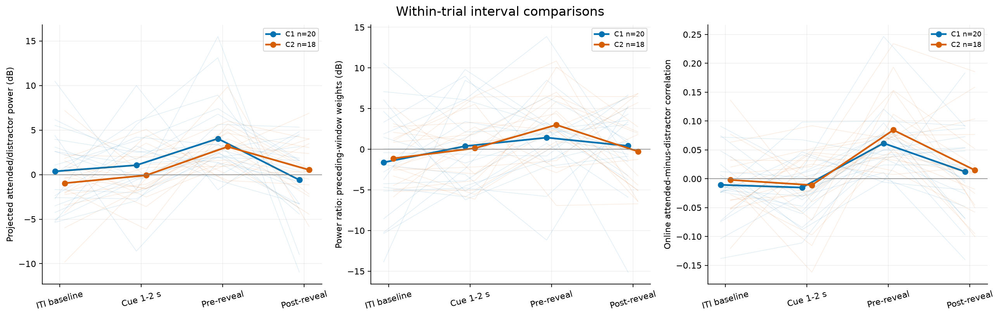

In [11]:
stage_cohort=metrics[metrics.long_reveal & metrics.post_complete].copy()
fig,axes=plt.subplots(1,3,figsize=(16,5),layout='constrained')
stages=['baseline','early','pre','post']
for ax,col,label in zip(axes,['power_db','power_db_previous','score_diff'],['Projected attended/distractor power (dB)','Power ratio: preceding-window weights (dB)','Online attended-minus-distractor correlation']):
 for cue,offset in [('c1',-.06),('c2',.06)]:
  g=stage_cohort[stage_cohort.cue.eq(cue)]
  values=g[[stage+'_'+col for stage in stages]].to_numpy()
  for row in values:ax.plot(np.arange(4)+offset,row,color=COLORS[cue],alpha=.12,lw=.7)
  ax.plot(np.arange(4)+offset,values.mean(0),'-o',color=COLORS[cue],lw=2,label=f'{cue.upper()} n={len(g)}')
 ax.axhline(0,color='gray',lw=.7);ax.set(xticks=range(4),xticklabels=['ITI baseline','Cue 1-2 s','Pre-reveal','Post-reveal'],ylabel=label);ax.tick_params(axis='x',rotation=15);ax.legend(fontsize=8)
savefig(fig,'interval_power_comparison','Within-trial interval comparisons',f'Fixed cohort of {len(stage_cohort)} revealed trials with latency >=4 s and complete +1 to +2 s post-reveal coverage. Thin lines are individual trials; thick lines are unweighted descriptive cue means. Formal contrasts in the tables balance cells. Pre/post reflect outcome selection and visual/response changes.')


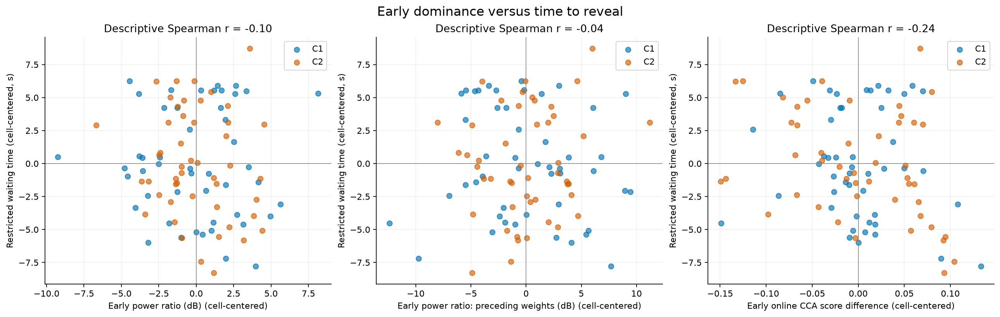

In [12]:
assoc=[];fig,axes=plt.subplots(1,3,figsize=(16,5),layout='constrained')
for ax,col,label in zip(axes,['early_power_db','early_power_db_previous','early_score_diff'],['Early power ratio (dB)','Early power ratio: preceding weights (dB)','Early online CCA score difference']):
 d=metrics[['block','cue','attended_hz',col,'wait15_s']].copy()
 for c in [col,'wait15_s']:d[c+'_resid']=d[c]-d.groupby(['block','cue','attended_hz'])[c].transform('mean')
 r=stats.spearmanr(d[col+'_resid'],d.wait15_s_resid).statistic;assoc.append(dict(metric=col,adjustment='center within block x cue x attended frequency',spearman_with_restricted_wait=r,n=96))
 for cue in ['c1','c2']:
  g=d[d.cue.eq(cue)];ax.scatter(g[col+'_resid'],g.wait15_s_resid,color=COLORS[cue],alpha=.65,label=cue.upper())
 ax.axhline(0,color='gray',lw=.7);ax.axvline(0,color='gray',lw=.7);ax.set(xlabel=label+' (cell-centered)',ylabel='Restricted waiting time (cell-centered, s)',title=f'Descriptive Spearman r = {r:.2f}');ax.legend()
savefig(fig,'early_power_vs_reveal_time','Early dominance versus time to reveal','96 trial means; cell centering controls additive session/cue/frequency means. No causal interpretation or confirmatory p-values.')
associations=pd.DataFrame(assoc);associations.to_csv(OUT/'timing_associations.csv',index=False)

## Fixed-cohort reveal dynamics and individual trials

Use the same revealed trials at every point from -3 to -0.2 s; latency >=4 s keeps source
windows post-cue. This removes changing membership, not selection by successful reveal.
Individual-trial heatmaps are sorted by cue then reveal latency. Missing tails stay missing.


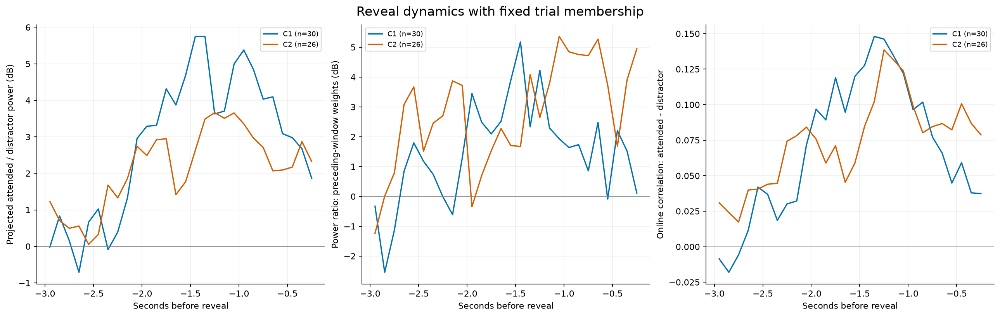


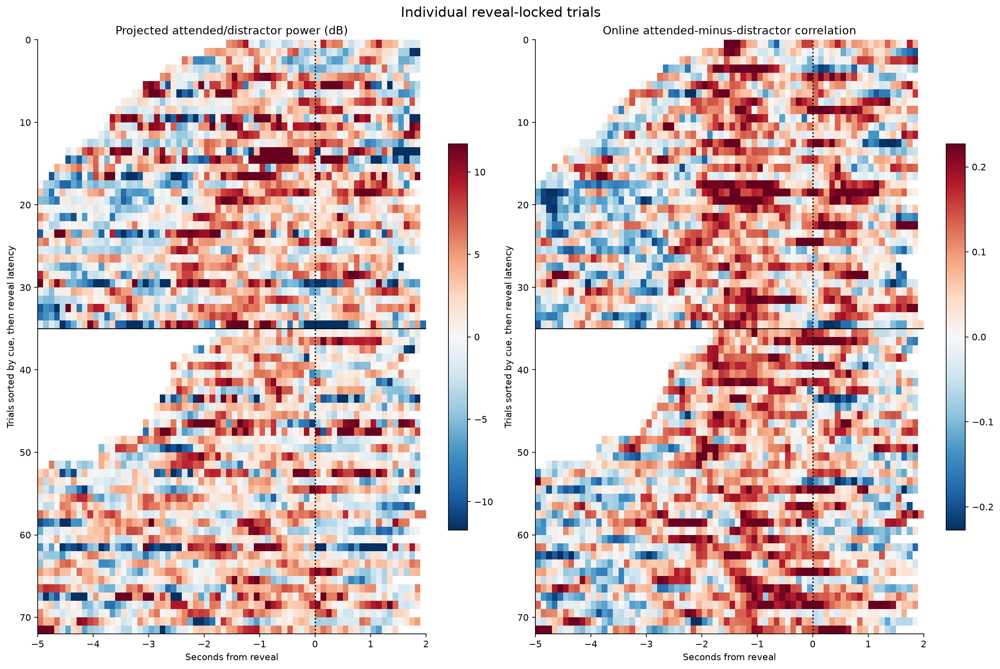

In [13]:
ids=metrics.loc[metrics.long_reveal,'trial_id'];d=windows[windows.trial_id.isin(ids)]
fig,axes=plt.subplots(1,3,figsize=(16,5),layout='constrained')
for ax,(col,label) in zip(axes,[METRICS[1],METRICS[2],METRICS[3]]):
 a=aligned(d,'reveal_time',col,['cue'],-3,-.2)
 for cue in ['c1','c2']:
  g=a[a.cue.eq(cue)];ax.plot(g.time,g['mean'],color=COLORS[cue],label=f'{cue.upper()} (n={sum(metrics.long_reveal & metrics.cue.eq(cue))})')
 ax.axhline(0,color='gray',lw=.7);ax.set(xlabel='Seconds before reveal',ylabel=label);ax.legend(fontsize=8)
savefig(fig,'fixed_cohort_reveal','Reveal dynamics with fixed trial membership',f'Same {len(ids)} trials throughout: revealed at >=4 s. Outcome-dependent selection remains.')
fig,axes=plt.subplots(1,2,figsize=(15,10),layout='constrained')
for ax,(col,label) in zip(axes,[('power_db','Projected attended/distractor power (dB)'),('score_diff','Online attended-minus-distractor correlation')]):
 d=windows[windows.revealed & windows.cue_time.ge(1)&windows.reveal_time.between(-5,1.9)].copy();d['bin']=np.floor((d.reveal_time+1e-8)/.1).astype(int)
 order=trials[trials.revealed].sort_values(['cue','reveal_s']).trial_id.tolist();mat=d.groupby(['trial_id','bin'])[col].mean().unstack().reindex(index=order,columns=range(-50,20))
 lim=np.nanquantile(abs(mat.to_numpy()),.95);im=ax.imshow(mat,aspect='auto',interpolation='nearest',extent=(-5,2,len(order),0),cmap='RdBu_r',vmin=-lim,vmax=lim)
 ax.axvline(0,color='black',ls=':');ax.axhline(sum(trials.revealed & trials.cue.eq('c1')),color='black',lw=1);ax.set(xlabel='Seconds from reveal',ylabel='Trials sorted by cue, then reveal latency',title=label);ax.grid(False);fig.colorbar(im,ax=ax,shrink=.65)
savefig(fig,'individual_reveal_heatmaps','Individual reveal-locked trials','Revealed C1 then C2 trials, sorted by latency. White=unavailable. Symmetric 95th absolute percentile limits for display only; all observations retained in calculations.')

## Separate instruction following from frequency asymmetry

Let D = rho17 - rho19. A cue-driven effect predicts D increases when attending 17 and
reverses when attending 19. A frequency asymmetry shifts D in the same direction under
both assignments. Balanced swaps allow a descriptive decomposition: the instruction
contrast is mean(D|attend17)-mean(D|attend19), while the frequency asymmetry is their
average. Compare early 1-2 s with each trial's ITI baseline. This does not identify whether
a frequency asymmetry originates in stimulus rendering, physiology, channels or estimation.

Assess spectral fitting sensitivity using local peak prominence: target-bin PSD divided
by the mean of non-target bins 16,18,20 Hz, calculated separately in each projected signal.
These local-background bins can contain taper leakage; this is a descriptive diagnostic,
not an absolute SNR or an independent test of a stimulus response.


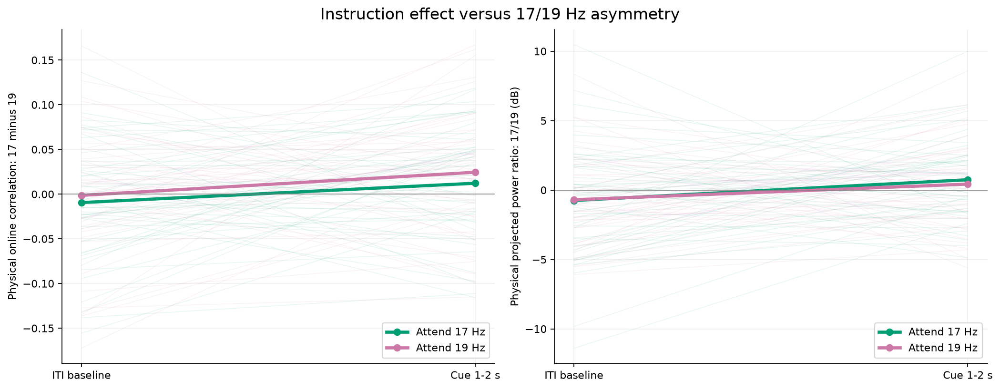


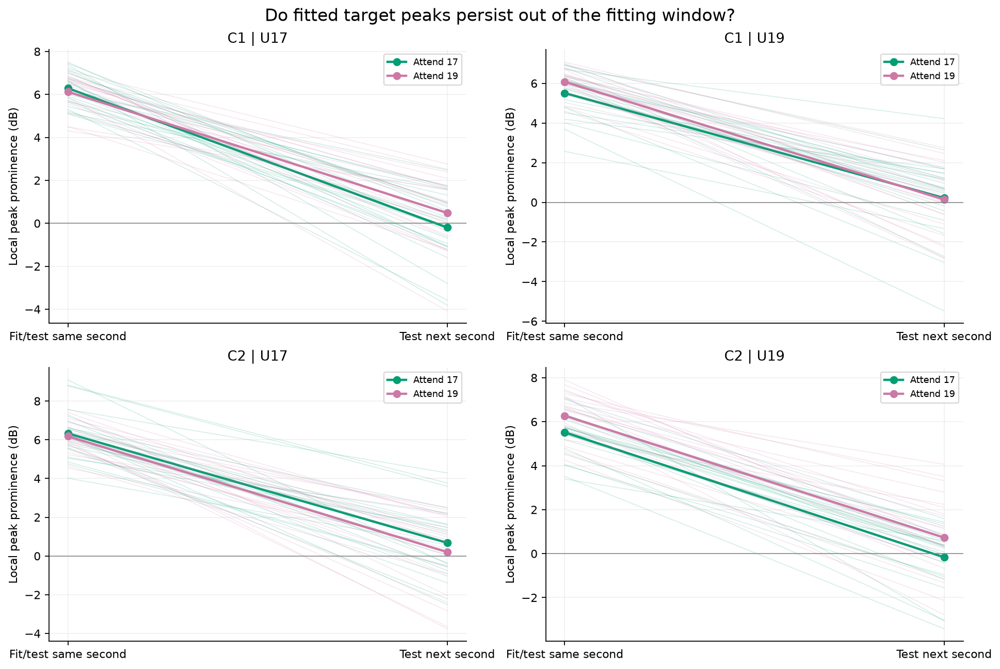

,metric,effect,estimate,ci_low,ci_high,n_trials
0,early_score_diff,instruction contrast in physical 17-minus-19 c...,-0.012278,-0.036530,0.014956,96
1,early_score_diff,physical 17-minus-19 frequency asymmetry,0.018349,0.006259,0.030698,96
2,early_minus_baseline_score_diff,instruction contrast in physical 17-minus-19 c...,-0.004204,-0.038851,0.032270,96
3,early_minus_baseline_score_diff,physical 17-minus-19 frequency asymmetry,0.023757,0.006555,0.041849,96
4,early_power_db,instruction contrast in physical 17-minus-19 c...,0.312341,-0.834222,1.441950,96
5,early_power_db,physical 17-minus-19 frequency asymmetry,0.586596,0.040704,1.165251,96
6,early_minus_baseline_power_db,instruction contrast in physical 17-minus-19 c...,0.365032,-1.579893,2.216226,96
7,early_minus_baseline_power_db,physical 17-minus-19 frequency asymmetry,1.310609,0.371636,2.248033,96


,method,target_hz,mean,median,count
0,preceding_window,17.0,0.291593,0.579837,96
1,preceding_window,19.0,0.228272,0.379507,96
2,same_window,17.0,6.232746,6.258762,96
3,same_window,19.0,5.842069,5.996354,96


In [14]:
decomposition=[]
for col in ['early_score_diff','early_minus_baseline_score_diff','early_power_db','early_minus_baseline_power_db']:
 point,low,high,n=balanced_contrast(metrics,col,'mean')
 decomposition.append(dict(metric=col,effect='instruction contrast in physical 17-minus-19 coordinates',estimate=2*point,ci_low=2*low,ci_high=2*high,n_trials=n))
 point,low,high,n=balanced_contrast(metrics,col,'frequency')
 decomposition.append(dict(metric=col,effect='physical 17-minus-19 frequency asymmetry',estimate=-point/2,ci_low=-high/2,ci_high=-low/2,n_trials=n))
decomposition=pd.DataFrame(decomposition);decomposition.to_csv(OUT/'attention_frequency_decomposition.csv',index=False)
fig,axes=plt.subplots(1,2,figsize=(13,5),layout='constrained')
for ax,col,label in zip(axes,['score_diff','power_db'],['Physical online correlation: 17 minus 19','Physical projected power ratio: 17/19 (dB)']):
 for hz,color in [(17.,FREQCOL[17.]),(19.,FREQCOL[19.])]:
  d=metrics[metrics.attended_hz.eq(hz)];sgn=1 if hz==17 else -1
  values=sgn*d[['baseline_'+col,'early_'+col]].to_numpy()
  for row in values:ax.plot([0,1],row,color=color,alpha=.09,lw=.7)
  ax.plot([0,1],values.mean(0),'-o',color=color,lw=3,label=f'Attend {hz:g} Hz')
 ax.axhline(0,color='gray',lw=.7);ax.set(xticks=[0,1],xticklabels=['ITI baseline','Cue 1-2 s'],ylabel=label);ax.legend()
savefig(fig,'attention_frequency_decomposition','Instruction effect versus 17/19 Hz asymmetry','48 trials per assignment. Both curves rising in physical 17-minus-19 coordinates indicates a common frequency asymmetry; opposite shifts would support instruction following. Thin lines: trial observations. Formal balanced contrasts are exported.')
peak_rows=[]
for t in trials.itertuples():
 for method,j in [('same_window',0),('preceding_window',1)]:
  spectrum=trial_spectra[t.trial_id][j]
  for component,target in enumerate(TARGETS_HZ):
   peak_rows.append(dict(trial_id=t.trial_id,block=t.block,cue=t.cue,attended_hz=t.attended_hz,target_hz=target,method=method,local_prominence_db=float(db(spectrum[int(target),component])-db(spectrum[[16,18,20],component].mean()))))
peak=pd.DataFrame(peak_rows);peak.to_csv(OUT/'projection_peak_prominence.csv',index=False)
peak_summary=peak.groupby(['method','target_hz']).local_prominence_db.agg(['mean','median','count']).reset_index();peak_summary.to_csv(OUT/'projection_peak_summary.csv',index=False)
fig,axes=plt.subplots(2,2,figsize=(12,8),layout='constrained')
for row,cue in enumerate(['c1','c2']):
 for col,target in enumerate(TARGETS_HZ):
  ax=axes[row,col]
  for hz,color in [(17.,FREQCOL[17.]),(19.,FREQCOL[19.])]:
   d=peak[peak.cue.eq(cue)&peak.target_hz.eq(target)&peak.attended_hz.eq(hz)]
   pair=d.pivot(index='trial_id',columns='method',values='local_prominence_db')[['same_window','preceding_window']]
   for v in pair.to_numpy():ax.plot([0,1],v,color=color,alpha=.18,lw=.7)
   ax.plot([0,1],pair.mean().to_numpy(),'-o',color=color,lw=2,label=f'Attend {hz:g}')
  ax.axhline(0,color='gray',lw=.7);ax.set(title=f'{cue.upper()} | U{target:g}',xticks=[0,1],xticklabels=['Fit/test same second','Test next second'],ylabel='Local peak prominence (dB)');ax.legend(fontsize=8)
savefig(fig,'fit_vs_next_window_peak','Do fitted target peaks persist out of the fitting window?','Full cue-to-reveal/timeout intervals; PSD averaged within each trial first. Local prominence uses target / mean(16,18,20 Hz) within its own projection. Target peaks that collapse out of fitting window provide weak evidence of a stable spatial signal.')
display(decomposition);display(peak_summary)

## Findings and interpretation

The current evidence favors an early task-related **17/19 Hz asymmetry** over a clear
instruction-following effect. The balanced swaps make this distinction possible: physical
17-minus-19 dominance increases under both attendance assignments. C1/C2 contrasts remain
uncertain, and their intervals do not establish equivalence.

Most target-peak prominence disappears when spatial filters are tested on a non-overlapping
second. This limits interpreting optimized spectra as independent evidence of a stable
SSVEP or attention signal. Online CCA still describes the control stream used by the game.

Before reveal, both increased attended correlation and decreased distractor correlation
contribute to the difference score. The smaller rise with independently evaluated power is
convergent description, but reveal-aligned changes remain selected by the feedback rule.
Timeouts split between never entering green and not obtaining reveal after entering green; these
are distinct control bottlenecks that response accuracy cannot distinguish.

All numerical estimates and uncertainty intervals follow below. They are exploratory,
conditional on this participant and four blocks; serial dependence across trials is not
modeled by the trial bootstrap. Software stimulus logs verify nominal modulation, not the
physical screen. No population inference or learning claim is made.

In [17]:

def format_contrast(metric,contrast):
 r=contrasts[(contrasts.metric==metric)&(contrasts.contrast==contrast)].iloc[0]
 return f'{r.estimate:.3f} [95% trial-bootstrap interval {r.ci_low:.3f}, {r.ci_high:.3f}], n={r.n_trials}'
lines=['# Leaf Game findings - 4 November 2026','',f'Four blocks pooled; 96 trials; {int(trials.revealed.sum())} reveals and {int((~trials.revealed).sum())} administrative timeouts.']
for cue,g in trials.groupby('cue'):lines.append(f'- {cue.upper()}: RMST15={g.wait15_s.mean():.2f} s; first-green-to-reveal median={g.green_to_reveal_s.median():.2f} s among reveals; {int(g.green_timeout.sum())} trials reached green but timed out.')
instruction=decomposition[(decomposition.metric=='early_minus_baseline_score_diff') & decomposition.effect.str.startswith('instruction')].iloc[0]
frequency=decomposition[(decomposition.metric=='early_minus_baseline_score_diff') & decomposition.effect.str.startswith('physical')].iloc[0]
lines+=['','Key interpretation:',f'- Early task-minus-ITI change favors 17 Hz independent of attendance: physical frequency asymmetry {frequency.estimate:.4f}, exploratory 95% interval [{frequency.ci_low:.4f}, {frequency.ci_high:.4f}]. Instruction-following contrast {instruction.estimate:.4f} [{instruction.ci_low:.4f}, {instruction.ci_high:.4f}] remains uncertain.', '- Optimized target peaks largely disappear on the next non-overlapping second. Treat these fitted peaks as descriptive, not independent validation of a stable response.', '- Reveal-aligned score increases contain both attended enhancement and distractor suppression. The stopping rule selects these trials, so this does not independently establish learning.', f'- Of {sum(~trials.revealed)} timeouts, {sum((~trials.revealed)&trials.first_green_s.isna())} never reached green and {sum(trials.green_timeout)} reached green without a reveal before the deadline.', '- Recorded border modulation matches logged 17/19 Hz on scheduled phase time (median regression R squared approximately 1); frame-end software timing gives median R squared approximately 0.99. No physical photodiode measurement is available.']
lines+=['','Exploratory balanced contrasts:']
for metric,contrast in [('wait15_s','C2 minus C1'),('wait15_s','attend19 minus attend17'),('early_score_diff','C2 minus C1'),('early_power_db','C2 minus C1'),('early_power_db_previous','C2 minus C1'),('early_score_diff','attend19 minus attend17'),('pre_minus_earlier_power_db','balanced paired change'),('pre_minus_earlier_power_db_previous','balanced paired change'),('pre_minus_earlier_score_diff','balanced paired change'),('pre_minus_earlier_score_att','balanced paired change'),('pre_minus_earlier_score_dist','balanced paired change')]:lines.append(f'- {metric}, {contrast}: {format_contrast(metric,contrast)}')
lines+=['','Trial-level early measure vs restricted waiting time (within-cell centered):']
for r in associations.itertuples():lines.append(f'- {r.metric}: descriptive Spearman r={r.spearman_with_restricted_wait:.3f}.')
lines+=['','Instruction versus physical frequency decomposition:']
for r in decomposition.itertuples():lines.append(f'- {r.metric}, {r.effect}: {r.estimate:.4f} [{r.ci_low:.4f}, {r.ci_high:.4f}].')
lines+=['','Projection peak prominence, mean over trial spectra:']
for r in peak_summary.itertuples():lines.append(f'- {r.method}, U{r.target_hz:g}: {r.mean:.2f} dB relative to local non-target bins.')
lines+=['','Pre-reveal growth is partly selected by the integration-and-hold rule, not independent evidence of learning. Intervals crossing zero leave effects uncertain. Preceding-window evaluation, fixed-cohort results and block plots are sensitivity checks, not confirmatory replications.']
findings='\n'.join(lines);(OUT/'findings.md').write_text(findings,encoding='utf-8');print(findings)
assert len(trials)==96 and len(trial_spectra)==96
assert np.isfinite(windows[['P17','P19','power_db','power_db_previous','score_diff']]).all().all()
assert np.all(windows.fit_start_seq==windows.seq-249) and spec_meta.groupby('trial_id').size().ge(10).all()
assert len(figures)==17
for row in hashes:assert hashlib.sha256((DATA_ROOT/row['path']).read_bytes()).hexdigest()==row['sha256']
pd.DataFrame(figures).to_csv(OUT/'plot_manifest.csv',index=False)
report=['<!doctype html><html><head><meta charset="utf-8"><title>Leaf dynamics - November 4</title><style>body{font-family:system-ui;max-width:1500px;margin:30px auto;padding:0 24px}img{max-width:100%}td,th{padding:7px;border:1px solid #ddd}pre{white-space:pre-wrap}</style></head><body>',f'<pre>{html.escape(findings)}</pre>',behavior_summary.to_html(index=False),contrasts.to_html(index=False)]
priority={'timing_across_blocks_c1_c2':0,'timing_across_blocks_frequency':1,'restricted_timing_across_blocks':2}
figures.sort(key=lambda f:priority.get(f['name'],3))
report=report[:1]+['<h1>Leaf Game: timing across blocks and neurofeedback dynamics</h1><p>Blocks 1-4 on the x-axis. Timing plots appear first; scientific findings and tables follow the figures.</p>']
for f in figures:report.append(f'<h2>{html.escape(f["title"])}</h2><img loading="lazy" src="{f["png"]}"><p>{html.escape(f["caption"])}</p><a href="{f["svg"]}">SVG</a>')
report.extend([f'<h2>Scientific findings</h2><pre>{html.escape(findings)}</pre>',behavior_summary.to_html(index=False),contrasts.to_html(index=False)])
report.append('</body></html>');(OUT/'index.html').write_text('\n'.join(report),encoding='utf-8');print('Verified unchanged inputs. Report:',OUT/'index.html')


# Leaf Game findings - 4 November 2026

Four blocks pooled; 96 trials; 72 reveals and 24 administrative timeouts.
- C1: RMST15=9.10 s; first-green-to-reveal median=0.99 s among reveals; 7 trials reached green but timed out.
- C2: RMST15=8.83 s; first-green-to-reveal median=0.99 s among reveals; 5 trials reached green but timed out.

Key interpretation:
- Early task-minus-ITI change favors 17 Hz independent of attendance: physical frequency asymmetry 0.0238, exploratory 95% interval [0.0066, 0.0418]. Instruction-following contrast -0.0042 [-0.0389, 0.0323] remains uncertain.
- Optimized target peaks largely disappear on the next non-overlapping second. Treat these fitted peaks as descriptive, not independent validation of a stable response.
- Reveal-aligned score increases contain both attended enhancement and distractor suppression. The stopping rule selects these trials, so this does not independently establish learning.
- Of 24 timeouts, 12 never reached green and 12 reached green wi